[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/10_Spam_Detection/HybridQSVM_SpamIDS_Chen2025.ipynb)

# Hybrid MLP + QSVM / VQC for spam and intrusion detection: Chen, Zhu and Li (2025) step by step

**Paper.** Zisheng Chen, Zirui Zhu, Xiangyang Li, *Cyber Threat Detection Enabled by Quantum Computing*, arXiv:2512.18493 (December 2025), https://arxiv.org/abs/2512.18493 (Johns Hopkins University, Information Security Institute).

**What this notebook does.** The paper builds a *hybrid* detector: a small classical neural network (an MLP encoder) squeezes
raw security data into a 12-number embedding, and only the first 2 or 4 numbers are handed to a tiny quantum model, either a
**quantum support vector machine (QSVM)** or a **variational quantum classifier (VQC)**. It tests this on two tasks, **spam filtering on
Ling-Spam** (e-mails, our topic folder) and **network intrusion detection on NSL-KDD**, and finally runs the best 4-qubit QSVM on an IBM
quantum computer. The notebook rebuilds that pipeline, explains every step in plain language, trains the classical baselines on
the same inputs, and ends with an honest table of *our* numbers next to the paper's.

**How to run.** Open it in Google Colab (button above), choose a **CPU runtime**, and use *Runtime -> Run all*. The committed outputs come from the full run (`FAST_MODE = False`: 3 seeds, 25 epochs, Gram matrices of 3,000 NSL-KDD flows, the paper's 100-sample device test), which took about 47 minutes on an 8-thread laptop CPU. Set `FAST_MODE = True` in the configuration cell for a class demo of about 8 minutes (2 seeds, smaller budgets, 40 device samples). The first cell installs pinned library versions; if Colab asks you to restart the runtime, do so and run all cells again.

**What you get at the end.** (1) Tables with accuracy, macro-F1, AUROC and AUPRC (mean and standard deviation over seeds) for the
classical linear head, the QSVM and the VQC with 2 and 4 qubits and for stronger classical models; (2) a numerical proof that our
fast kernel code, Qiskit and PennyLane compute the same kernel and the same circuit outputs; (3) a noisy-device experiment
on a model of IBM Torino (a *simulation*, not a real quantum computer unless you add an IBM token); (4) a cell-by-cell verdict
"reproduced / not reached / exceeded" against the paper's Tables III to V.

## The paper in one page

**Problem.** Intrusion detectors and spam filters have to catch rare, borderline cases under tight feature and compute budgets. The authors ask
whether a *tiny* quantum component (2 to 4 qubits), placed after a classical encoder, can match or beat classical models, and how much of the
simulated result survives on a real, noisy IBM device.

**Decision.** Binary: attack (1) vs normal (0) on NSL-KDD; spam (1) vs ham (0) on Ling-Spam.

**Method.**
1. *Classical encoder*: a few `Linear -> LayerNorm -> GELU -> Dropout` blocks, an embedding head of size 12 that is **L2-normalised** (so every coordinate lies in [-1, 1]) and a linear 2-class head. Trained with class-balanced cross-entropy.
2. *QSVM*: take the first `q` embedding coordinates, scale them robustly to [-1, 1], turn them into angles `theta = pi * x`, load them with a **ZZ feature map** (Hadamards, single-qubit phases and all-to-all ZZ phases), and use the **fidelity kernel** `k(a,b) = |<phi(a)|phi(b)>|^2`. The Gram matrix is *double-centred* and fed to an ordinary SVM with `kernel="precomputed"`; the penalty `C` is chosen by cross-validation on F-beta (beta = 2, recall-weighted) and the decision threshold is tuned on validation data.
3. *VQC*: the same angles, but a trainable circuit: `L` blocks of [ZZ feature map -> RY, RZ rotations -> chain of CZ gates] (**data re-uploading**), readout `<Z x ... x Z>` used as a logit, binary cross-entropy, Adam, early stopping.
4. *Hardware*: the 4-qubit QSVM is run on `ibm_torino` for about 100 test e-mails or flows, with readout mitigation (M3) and dynamical decoupling (XY8), 1024 shots.

**Data.** NSL-KDD (`KDDTrain+` for train/validation, `KDDTest+` for test, binary labels, 3 categorical columns) and Ling-Spam (2,893 e-mails of which 481 are spam, TF-IDF features).

**Experiment.** A 2 x 2 x 2 design (2 or 4 qubits, QSVM or VQC, Qiskit or PennyLane); results in Tables III (NSL-KDD) and IV (Ling-Spam), and the hardware run in Table V.

**Claims we can test.**
* Table III / IV numbers (accuracy, macro-F1, AUROC, AUPRC) for the classical head and the four quantum heads.
* The 4-qubit QSVM is the best configuration on both datasets.
* Quantum heads match tuned classical models on the same features.
* Qiskit and PennyLane give "no difference in performance".
* Hardware (Table V: NSL-KDD 0.840 accuracy, Ling-Spam 0.990) stays close to the simulator.

**Reading the tables.** The paper's tables have ten rows `C0 ... C9`, while the text defines eight configurations `C1 ... C8` (Table I). Rows `C5 ... C9` repeat `C0 ... C4` *digit for digit*. We therefore read the table as
`C0` = classical MLP with its linear head, `C1` / `C2` = QSVM with 2 / 4 qubits, `C3` / `C4` = VQC with 2 / 4 qubits, and treat `C5 ... C9` as copies. This reading is consistent with the text ("best model = hybrid MLP-QSVM, 4 qubits" is `C2`), but it is our interpretation.

## What follows the paper and what had to be chosen

Where the paper is silent we made a choice; each one is marked `# CHOICE:` in the code or listed in the configuration cell.

| Item | Paper | This notebook |
|---|---|---|
| Ling-Spam source and variant | "lingspam public tree", variant not stated | official AUEB archive (GitHub mirror with identical files as fallback), variant `bare` |
| Ling-Spam labels and split | `spmsg*` = spam; stratified, test 20 %, validation 20 % of the rest | same; `random_state` = seed |
| TF-IDF | lower-case, English stop words, `min_df=2`, `max_df=0.95`, "up to n-grams" | unigrams only, vocabulary fitted on the training split |
| NSL-KDD split | `KDDTrain+` -> train/validation (20 %), `KDDTest+` -> test | same, plus an extra **in-distribution hold-out** (10 % of `KDDTrain+`) as a diagnostic; FAST mode scores a stratified 6,000-row part of `KDDTest+` |
| NSL-KDD preprocessing | binary label, drop `difficulty`, standardise numerics, rare levels (< 50) -> `RARE`, one-hot | same; levels unseen in training also become `RARE` |
| Encoder size | blocks with LayerNorm/GELU/Dropout 0.15, embedding 12; widths not given | hidden widths (128, 64), embedding 12 |
| Encoder training | 25 epochs, batch 256, lr 1e-3, weight decay 1e-4, patience 8, balanced weights, early stop on validation F1 | same (FAST: 10 epochs) |
| QSVM angles | unit-norm embedding, robust 5-95 % scaling, clip to [-1, 1], `theta = pi x` | same |
| ZZ feature map | full entanglement; repetitions "configurable" | `reps = 2` |
| Kernel | squared fidelity from statevectors, double-centred | exact statevectors, vectorised numpy; **checked against Qiskit and PennyLane** |
| SVM `C` and threshold | CV on F-beta (beta = 2); threshold tuned on validation | `C in {0.1, 1, 10, 100}`, 3-fold (FAST) or 5-fold CV; same threshold rule |
| Gram matrix size | not stated (126k NSL-KDD rows cannot fit a Gram matrix) | Ling-Spam: all 1,851 training e-mails; NSL-KDD: stratified 800 (FAST) or 3,000 flows |
| VQC circuit | ZZ feature map (reps 1, linear) + TwoLocal (RY, RZ, CZ), re-upload `L`, `<Z...Z>`, BCE, Adam | same circuit, `L = 2`; trained in **PennyLane** (fast batched back-propagation); the same circuit is rebuilt in **Qiskit `EstimatorQNN`** and compared numerically |
| VQC training | "all trainables" (encoder and circuit) with lr 1e-3 | encoder (initialised from the trained one) and circuit trained jointly; circuit learning rate 1e-2 (a larger step suits our short budgets) |
| VQC training set | not stated | Ling-Spam: all; NSL-KDD: stratified 4,000 (FAST) or 12,000 rows |
| Seeds | "multiple random restarts" | 2 seeds (FAST) or 3 seeds, mean +/- std |
| Classical baselines | only `C0` (the encoder's own linear head) | `C0`, plus RBF-SVC and random forest on the *same* `q` angles, plus a forest / linear SVM on all features |
| Noise in training | depolarising 1e-3 / 1e-2 in some runs | not used in training (ideal statevector); noise only in the device proxy |
| Hardware | IBM Torino, M3 readout mitigation, XY8 dynamical decoupling, about 100 samples | **proxy**: Aer with the `FakeTorino` noise model, our own tensored readout mitigation (not M3), no dynamical decoupling. Real hardware runs only if `IBM_TOKEN` is set |

## 0. Install, configuration and imports

Everything tunable is in the configuration cell. `FAST_MODE = True` gives the class-demo budgets; the comment next to each constant
gives the full-run value. Seeds are fixed everywhere: Python/NumPy (`SEED`), PyTorch, scikit-learn `random_state`, `algorithm_globals`, the Aer simulator and the transpiler.

In [1]:
import sys, importlib
IN_COLAB = "google.colab" in sys.modules

def _have(mod):
    try:
        importlib.import_module(mod)
        return True
    except Exception:
        return False

# Pinned to the versions this notebook was tested with. Colab already ships numpy, pandas,
# scikit-learn, matplotlib and torch. A runtime restart may be requested after the install:
# if so, restart and run all cells again from the top.
if IN_COLAB or not all(_have(m) for m in ["qiskit", "qiskit_aer", "qiskit_machine_learning", "qiskit_ibm_runtime", "pennylane", "torch"]):
    !pip -q install "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" "pennylane==0.45.1" pylatexenc

In [2]:
import os
SEED = 42                 # master seed
FAST_MODE = False         # True: small budgets for a class demo (about 10 min). False: full budgets (see section 0)
IBM_TOKEN = ""            # optional: set an IBM Quantum token to also run the real-hardware cell. Empty = skipped.
IBM_BACKEND = "ibm_torino"
DATA_DIR = "qc151_data"   # downloaded data is cached here
LOCAL_LINGSPAM_TGZ = ""   # optional: path of an uploaded lingspam_public.tar.gz
LOCAL_NSL_DIR = ""        # optional: folder containing KDDTrain+.txt and KDDTest+.txt

# --- datasets / splits (paper Section V)
DATASETS = ["lingspam", "nslkdd"]
TEST_SIZE = 0.20          # Ling-Spam: 20 % test, then 20 % of the remainder as validation
VAL_SIZE = 0.20           # NSL-KDD: 20 % of KDDTrain+ as validation
INTERNAL_SIZE = 0.10      # CHOICE: extra in-distribution hold-out carved from KDDTrain+ (diagnostic only)
LING_VARIANT = "bare"     # CHOICE: Ling-Spam variant (bare / lemm / stop / lemm_stop); paper does not say
TFIDF_MIN_DF, TFIDF_MAX_DF = 2, 0.95

# --- classical MLP encoder (paper Table II, Section VI-A)
D_EMB = 12                # embedding size (paper default)
HIDDEN = (128, 64)        # CHOICE: hidden widths are not given
DROPOUT = 0.15
BATCH, LR, WD, PATIENCE = 256, 1e-3, 1e-4, 8
EPOCHS = 10 if FAST_MODE else 25
BETA = 2.0                # F-beta used for threshold / C selection (paper: beta = 2, recall on the attack/spam class)

# --- quantum heads
QUBITS = (2, 4)
ZZ_REPS = 2               # CHOICE: repetitions of the QSVM ZZ feature map (paper: "configurable")
C_GRID = (0.1, 1.0, 10.0, 100.0)
TUNE_REPS = (2, 1)         # extra "QSVM-tuned" variant: feature-map repetitions and angle scale (bandwidth) chosen by CV on the training split
TUNE_BW = (1.0, 0.5, 0.25)
CV_FOLDS = 3 if FAST_MODE else 5
VQC_L = 2                 # CHOICE: number of data re-uploading blocks
VQC_EPOCHS = 6 if FAST_MODE else 25
VQC_LR_Q = 1e-2           # CHOICE: learning rate of circuit parameters (paper: 1e-3 for everything)

# --- sample budgets (the simulator cannot take all 126k NSL-KDD rows into a Gram matrix)
N_SEEDS = 2 if FAST_MODE else 3
SEEDS = [SEED + 1000 * i for i in range(N_SEEDS)]
NSL_ENC_N = 20_000 if FAST_MODE else None      # rows used to train the encoder (None = all)
N_KERNEL_TRAIN = {"lingspam": None, "nslkdd": 800 if FAST_MODE else 3000}   # Gram matrix size (None = all train)
N_VAL_EVAL = {"lingspam": None, "nslkdd": 1500}                             # validation rows used for threshold
N_VQC_TRAIN = {"lingspam": None, "nslkdd": 4000 if FAST_MODE else 12_000}
NSL_TEST_N = 6000 if FAST_MODE else None       # evaluate on a stratified part of KDDTest+ (None = all 22,544)

# --- noisy-device proxy (paper Section VII-H)
SHOTS = 1024
HW_N_TEST = 40 if FAST_MODE else 100
HW_N_REF = 16 if FAST_MODE else 64
HW_ALL_SUBTYPES = not FAST_MODE   # NSL-KDD device subset: include every attack sub-type at least once (paper), only in the full run

os.makedirs(DATA_DIR, exist_ok=True)

In [3]:
import io, re, time, tarfile, warnings, copy, math
from pathlib import Path
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, fbeta_score, roc_auc_score, average_precision_score,
                             confusion_matrix, precision_recall_curve)
import qiskit, qiskit_aer, qiskit_machine_learning, pennylane as qml
from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.utils import algorithm_globals
warnings.filterwarnings("ignore")
algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED); np.random.seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))
print({"qiskit": qiskit.__version__, "qiskit-aer": qiskit_aer.__version__, "qiskit-ml": qiskit_machine_learning.__version__,
       "pennylane": qml.__version__, "torch": torch.__version__, "sklearn": sklearn.__version__, "numpy": np.__version__})
print("FAST_MODE =", FAST_MODE, "| seeds =", SEEDS)

{'qiskit': '2.5.2', 'qiskit-aer': '0.17.2', 'qiskit-ml': '0.9.1', 'pennylane': '0.45.1', 'torch': '2.14.1+cpu', 'sklearn': '1.9.1', 'numpy': '2.5.4'}
FAST_MODE = False | seeds = [42, 1042, 2042]


## 1. The data

Two public data sets, both downloaded here and cached in `DATA_DIR`.

* **Ling-Spam** (Androutsopoulos et al., 2000): 2,893 e-mails from a linguistics mailing list, of which 481 are spam. A message is spam if its file name starts with `spmsg`.
* **NSL-KDD** (Tavallaee et al., 2009): the de-duplicated version of the KDD Cup 1999 network-intrusion data: 41 flow features plus an attack label; `KDDTrain+` has 125,973 flows and `KDDTest+` has 22,544. The test file has a *different* attack mix (57 % attacks, including attack types never seen in training), which is what makes NSL-KDD hard.

If the AUEB server is unreachable (its certificate chain is incomplete on some systems) the notebook falls back to a GitHub mirror that we compared with the official archive file by file (identical MD5 for all 2,893 messages).

In [4]:
LING_URLS = ["https://www2.aueb.gr/users/ion/data/lingspam_public.tar.gz",             # official (incomplete TLS chain on some systems)
             "https://codeload.github.com/llhyatt98/SpamFilter/zip/HEAD"]               # GitHub mirror of the same files
NSL_URLS = {"KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                              "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"],
            "KDDTest+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                             "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"]}

def fetch(urls, dest):
    """Download the first working URL to dest (cached). Certificates are always verified."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=180); r.raise_for_status()
            dest.write_bytes(r.content); print("downloaded", u, f"({len(r.content)/1e6:.1f} MB)")
            return dest
        except Exception as e:
            last = e; print("failed:", u, type(e).__name__)
    raise RuntimeError(f"could not download {dest.name}: {last}. Upload it and set the LOCAL_* option in the config cell.")

def load_lingspam():
    """Reads the Ling-Spam corpus from the official tar.gz or, if the AUEB server is unreachable, from a GitHub mirror
    (zip of the same files; checked once against the official archive: all 2,893 'bare' messages have identical MD5)."""
    if LOCAL_LINGSPAM_TGZ:
        src = Path(LOCAL_LINGSPAM_TGZ)
    else:
        try:
            src = fetch(LING_URLS[:1], Path(DATA_DIR) / "lingspam_public.tar.gz")
        except RuntimeError:
            src = fetch(LING_URLS[1:], Path(DATA_DIR) / "lingspam_mirror.zip")
    items = []                                     # (path inside the 'bare' folder, raw bytes)
    marker = f"/{LING_VARIANT}/"
    if str(src).endswith((".tar.gz", ".tgz")):
        with tarfile.open(src) as tf:
            for m in tf.getmembers():
                if m.isfile() and marker in m.name and m.name.endswith(".txt"):
                    items.append((m.name.split(marker, 1)[1], tf.extractfile(m).read()))
    else:
        import zipfile
        with zipfile.ZipFile(src) as zf:
            for n in zf.namelist():
                if "lingspam_public" in n and marker in n and n.endswith(".txt"):
                    items.append((n.split(marker, 1)[1], zf.read(n)))
    items.sort(key=lambda it: it[0])               # deterministic order
    texts = np.array([b.decode("latin-1") for _, b in items], dtype=object)
    labels = np.array([1 if os.path.basename(p).startswith("spmsg") else 0 for p, _ in items])   # paper: spmsg* = spam, others = ham
    return texts, labels

NSL_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment","urgent","hot",
            "num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root","num_file_creations",
            "num_shells","num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count","srv_count",
            "serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate",
            "srv_diff_host_rate","dst_host_count","dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
            "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate","dst_host_srv_serror_rate",
            "dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty"]

def load_nsl():
    out = []
    for fn, urls in NSL_URLS.items():
        p = Path(LOCAL_NSL_DIR) / fn if LOCAL_NSL_DIR else fetch(urls, Path(DATA_DIR) / fn)
        out.append(pd.read_csv(p, header=None, names=NSL_COLS).drop(columns="difficulty"))   # paper: difficulty is dropped
    return out

texts, y_text = load_lingspam()
nsl_train_raw, nsl_test_raw = load_nsl()
print(f"Ling-Spam ({LING_VARIANT}): {len(texts)} e-mails, {y_text.sum()} spam ({y_text.mean():.1%})")
print(f"NSL-KDD: KDDTrain+ {nsl_train_raw.shape}, KDDTest+ {nsl_test_raw.shape}")
print("train attack share:", round((nsl_train_raw.label != 'normal').mean(), 3), "| test attack share:", round((nsl_test_raw.label != 'normal').mean(), 3))
print("\nExample spam e-mail (first 300 characters):\n", texts[np.where(y_text == 1)[0][0]][:300])

failed: https://www2.aueb.gr/users/ion/data/lingspam_public.tar.gz SSLError


downloaded https://codeload.github.com/llhyatt98/SpamFilter/zip/HEAD (6.0 MB)


downloaded https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt (19.1 MB)


downloaded https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt (3.4 MB)


Ling-Spam (bare): 2893 e-mails, 481 spam (16.6%)
NSL-KDD: KDDTrain+ (125973, 42), KDDTest+ (22544, 42)
train attack share: 0.465 | test attack share: 0.569

Example spam e-mail (first 300 characters):
 Subject: great part-time or summer job !

* * * * * * * * * * * * * * * we have display boxes with credit applications that we need to place in the small owner-operated stores in your area . here is what you do : 1 . introduce yourself to the store owner or manager . 2 . use our 90 % effective scrip


## 2. Preprocessing: every transform is fitted on the training split only

Ling-Spam is turned into TF-IDF vectors (about 21,000 sparse word features). NSL-KDD gets one-hot protocol/service/flag columns
(rare categories merged into `RARE`) and standardised numeric columns (about 110 features). The vocabulary, the rare-category list and
the scalers all come from the training rows; validation and test rows are only *transformed*, which is the paper's "no leakage" rule.
The validation split is used to stop training and to pick the decision threshold; the test split is touched only for the final numbers.

In [5]:
def strat_sub(y, n, seed):
    """Stratified subsample of n indices (all if n is None or too big)."""
    idx = np.arange(len(y))
    if n is None or n >= len(y):
        return idx
    keep, _ = train_test_split(idx, train_size=n, stratify=y, random_state=seed)
    return np.sort(keep)

def prep_lingspam(seed):
    """Returns {'train','val','test'} -> (X, y) with a TF-IDF vocabulary fitted on the training split only."""
    idx = np.arange(len(texts))
    tv, te = train_test_split(idx, test_size=TEST_SIZE, stratify=y_text, random_state=seed)
    tr, va = train_test_split(tv, test_size=VAL_SIZE, stratify=y_text[tv], random_state=seed)
    vec = TfidfVectorizer(lowercase=True, stop_words="english", min_df=TFIDF_MIN_DF, max_df=TFIDF_MAX_DF, dtype=np.float32)
    Xtr = vec.fit_transform(texts[tr])
    sets = {"train": (Xtr, y_text[tr]), "val": (vec.transform(texts[va]), y_text[va]), "test": (vec.transform(texts[te]), y_text[te])}
    return sets, {"n_features": Xtr.shape[1]}

CATS = ["protocol_type", "service", "flag"]

def prep_nsl(seed):
    """Frequency-bucketed one-hot + standardised numerics, fitted on the training split only."""
    full = nsl_train_raw
    y_all = (full.label != "normal").astype(int).values
    idx = np.arange(len(full))
    rest, internal = train_test_split(idx, test_size=INTERNAL_SIZE, stratify=y_all, random_state=seed)
    tr, va = train_test_split(rest, test_size=VAL_SIZE, stratify=y_all[rest], random_state=seed)
    freq = {c: set(full.iloc[tr][c].value_counts().loc[lambda s: s >= 50].index) for c in CATS}   # paper: min count 50 -> RARE
    def bucket(df):
        d = df[CATS + [c for c in NSL_COLS if c not in CATS + ["label", "difficulty"]]].copy()
        for c in CATS:
            d[c] = d[c].where(d[c].isin(freq[c]), "RARE")          # unseen levels also become RARE
        return d
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    num_cols = [c for c in bucket(full.iloc[:5]).columns if c not in CATS]
    sc = StandardScaler()
    dtr = bucket(full.iloc[tr])
    fit_parts = (ohe.fit(dtr[CATS]), sc.fit(dtr[num_cols]))
    def tf(df):
        d = bucket(df)
        return np.hstack([ohe.transform(d[CATS]), sc.transform(d[num_cols])]).astype(np.float32)
    yt = (nsl_test_raw.label != "normal").astype(int).values
    te_keep = strat_sub(yt, NSL_TEST_N, seed)
    sets = {"train": (tf(full.iloc[tr]), y_all[tr]), "val": (tf(full.iloc[va]), y_all[va]),
            "test": (tf(nsl_test_raw.iloc[te_keep]), yt[te_keep]), "internal": (tf(full.iloc[internal]), y_all[internal])}
    meta = {"n_features": sets["train"][0].shape[1], "test_attack_type": nsl_test_raw.label.values[te_keep]}
    return sets, meta

PREP = {"lingspam": prep_lingspam, "nslkdd": prep_nsl}
_s, _m = prep_lingspam(SEED)
print("Ling-Spam split sizes:", {k: (v[0].shape[0], int(v[1].sum())) for k, v in _s.items()}, "| TF-IDF features:", _m["n_features"])
_s, _m = prep_nsl(SEED)
print("NSL-KDD split sizes:", {k: (v[0].shape[0], int(v[1].sum())) for k, v in _s.items()}, "| input features:", _m["n_features"])
del _s, _m

Ling-Spam split sizes: {'train': (1851, 308), 'val': (463, 77), 'test': (579, 96)} | TF-IDF features: 21614


NSL-KDD split sizes: {'train': (90700, 42214), 'val': (22675, 10553), 'test': (22544, 12833), 'internal': (12598, 5863)} | input features: 112


## 3. Metrics and the decision threshold

The paper reports accuracy, **macro-F1** (the F1 of each class, averaged), **AUROC** and **AUPRC** (area under the precision-recall curve of the attack/spam class). The positive class is attack/spam.
Models give a *score*; the paper turns it into a label with a **threshold tuned on the validation set to maximise F-beta with beta = 2** (recall counts four times more than precision, because a missed attack is worse than a false alarm). We report both that tuned threshold ("tuned") and the plain threshold 0 ("default"). AUROC and AUPRC do not depend on the threshold.

In [6]:
def best_threshold(y, score, beta=BETA):
    """Threshold maximising F-beta of the positive class on validation scores."""
    p, r, t = precision_recall_curve(y, score)
    f = (1 + beta**2) * p[:-1] * r[:-1] / np.maximum(beta**2 * p[:-1] + r[:-1], 1e-12)
    return float(t[int(np.nanargmax(f))])

def metric_row(y, score, thr):
    pred = (score >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(acc=accuracy_score(y, pred), f1_macro=f1_score(y, pred, average="macro"),
                auroc=roc_auc_score(y, score), auprc=average_precision_score(y, score),
                recall_pos=tp / max(tp + fn, 1), fpr=fp / max(fp + tn, 1), tp=tp, fp=fp, fn=fn, tn=tn)

RESULTS = []   # one dict per (dataset, seed, model, q, evalset, threshold mode)

def record(dataset, seed, model, q, y_val, s_val, y_sets, s_sets, seconds):
    thr_t = best_threshold(y_val, s_val)
    for ev in y_sets:
        for mode, thr in (("tuned", thr_t), ("default", 0.0)):
            RESULTS.append(dict(dataset=dataset, seed=seed, model=model, q=q, evalset=ev, thr=mode, seconds=seconds,
                                **metric_row(y_sets[ev], s_sets[ev], thr)))

## 4. The classical encoder (MLP)

This is the part of the model that does the heavy lifting: it learns, from all ~21,000 or ~110 input features, a 12-dimensional
direction `e` on the unit sphere. Two heads sit on top of `e`: a linear 2-class head (this is the paper's purely classical model `C0`) and, later, the quantum heads that
read only the first `q` coordinates of `e`. Because `||e|| = 1`, every coordinate lies in [-1, 1] and can be used as a rotation angle.

In [7]:
class Encoder(nn.Module):
    """Linear -> LayerNorm -> GELU -> Dropout blocks, an L2-normalised embedding head and a 2-class linear head."""
    def __init__(self, d_in, hidden=HIDDEN, d_emb=D_EMB, p=DROPOUT):
        super().__init__()
        blocks, d = [], d_in
        for h in hidden:
            blocks += [nn.Linear(d, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(p)]
            d = h
        self.backbone = nn.Sequential(*blocks)
        self.emb = nn.Linear(d, d_emb)
        self.head = nn.Linear(d_emb, 2)
    def forward(self, x):
        e = F.normalize(self.emb(self.backbone(x)), dim=1)
        return self.head(e), e

def dense(X, idx):
    b = X[idx]
    b = b.toarray() if hasattr(b, "toarray") else b
    return torch.from_numpy(np.asarray(b, dtype=np.float32))

@torch.no_grad()
def encode(model, X, chunk=4096):
    model.eval(); L, E = [], []
    for i in range(0, X.shape[0], chunk):
        lg, e = model(dense(X, np.arange(i, min(i + chunk, X.shape[0]))))
        L.append(lg.numpy()); E.append(e.numpy())
    return np.vstack(L), np.vstack(E)

def train_encoder(Xtr, ytr, Xva, yva, seed, epochs=EPOCHS, verbose=True):
    """Class-balanced cross-entropy, Adam + weight decay, early stopping on validation F1 of the positive class."""
    torch.manual_seed(seed); g = np.random.default_rng(seed)
    model = Encoder(Xtr.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    w = torch.tensor(len(ytr) / (2 * np.bincount(ytr)), dtype=torch.float32)          # class_weight='balanced'
    best, best_state, bad, hist = -1, None, 0, []
    ytr_t = torch.from_numpy(ytr)
    for ep in range(epochs):
        model.train(); perm = g.permutation(len(ytr)); tl = 0
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            loss = F.cross_entropy(model(dense(Xtr, b))[0], ytr_t[b], weight=w)
            opt.zero_grad(); loss.backward(); opt.step(); tl += loss.item() * len(b)
        lv, _ = encode(model, Xva)
        f1 = f1_score(yva, lv.argmax(1))
        hist.append((tl / len(perm), f1))
        if f1 > best + 1e-4:
            best, bad, best_state = f1, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    if verbose: print(f"  encoder: {len(hist)} epochs, best val F1 {best:.4f}")
    return model, hist

## 5. The quantum feature map and kernel

A **feature map** is a quantum circuit that loads a data point `x` into the state of `q` qubits. The ZZ feature map of the paper repeats `reps` times:
a Hadamard on every qubit, a phase `2*x_i` on qubit `i`, and for every *pair* of qubits a phase `2*(pi - x_i)*(pi - x_j)` applied through two CNOT gates. The
**kernel** between two points is the squared overlap of their states, `|<phi(a)|phi(b)>|^2`: a similarity between 0 and 1 that a classical SVM can use.

Because all phase gates are diagonal, the state of a whole batch can be computed with a few lines of NumPy instead of building a circuit per sample (22,544 test flows x 3,000 training flows would otherwise be very slow). To be sure this shortcut is right, the cell compares it with Qiskit's own `zz_feature_map` and `Statevector`.
The Gram matrix is then **double-centred** (subtract the mean feature vector in the quantum feature space, exactly as in kernel PCA) before the SVM sees it.

numpy ZZ-feature-map kernel == Qiskit Statevector kernel:

 True


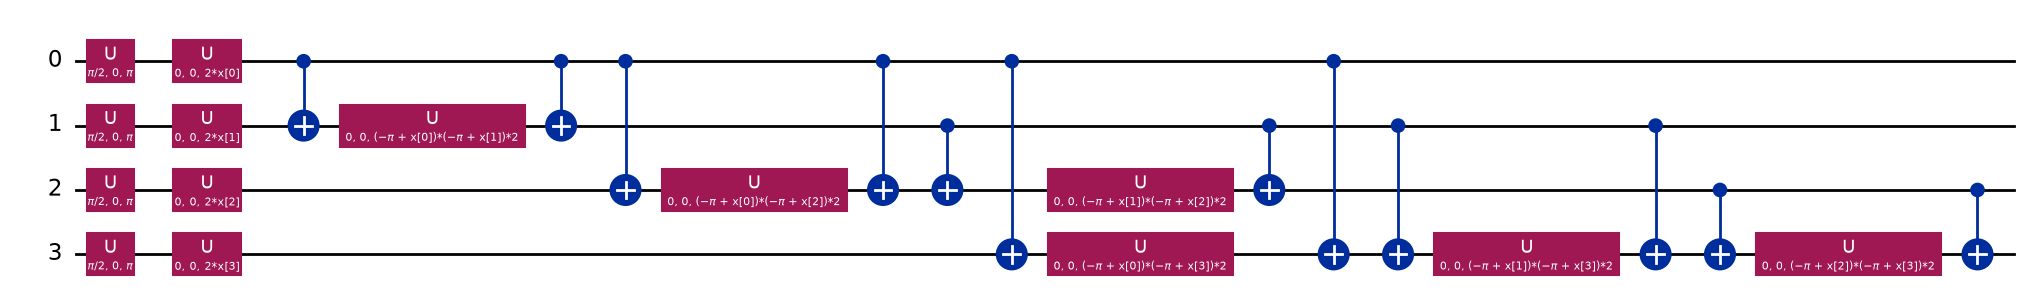

In [8]:
def zz_states(theta, reps=ZZ_REPS, entanglement="full"):
    """Exact statevectors of Qiskit's zz_feature_map for many samples at once (vectorised numpy).
    One repetition = H on all qubits, P(2 x_i) on each qubit, then CX-P(2 (pi-x_i)(pi-x_j))-CX on each pair."""
    N, q = theta.shape; dim = 2 ** q
    z = (np.arange(dim)[:, None] >> np.arange(q)[None, :]) & 1                       # bit i of basis index = qubit i
    pairs = [(i, j) for i in range(q) for j in range(i + 1, q)] if entanglement == "full" else [(i, i + 1) for i in range(q - 1)]
    phase = 2 * theta @ z.T
    for i, j in pairs:
        phase = phase + 2 * (np.pi - theta[:, [i]]) * (np.pi - theta[:, [j]]) * (z[:, i] ^ z[:, j])[None, :]
    D = np.exp(1j * phase)
    H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2); Hn = np.array([[1.0]])
    for _ in range(q): Hn = np.kron(Hn, H1)
    psi = np.zeros((N, dim), complex); psi[:, 0] = 1
    for _ in range(reps):
        psi = (psi @ Hn.T) * D
    return psi

def fid_kernel(A, B, reps=ZZ_REPS, bw=1.0):
    """k(a, b) = |<phi(a)|phi(b)>|^2 ; bw rescales all angles (bw = 1 is the paper)."""
    SA, SB = zz_states(bw * A, reps), zz_states(bw * B, reps)
    return np.abs(SA.conj() @ SB.T) ** 2

def center_train(K):
    col = K.mean(0)
    return K - col[None, :] - col[:, None] + K.mean(), col, K.mean()

def center_test(Ks, col, tot):
    return Ks - Ks.mean(1, keepdims=True) - col[None, :] + tot

# --- sanity check against Qiskit's own circuit library and Statevector (independent implementation)
def qiskit_state(x, reps=ZZ_REPS, entanglement="full"):
    fm = zz_feature_map(len(x), reps=reps, entanglement=entanglement)
    return Statevector(fm.assign_parameters(dict(zip(fm.parameters, x)))).data

_t = rng.uniform(-np.pi, np.pi, size=(6, 4))
mine = zz_states(_t, ZZ_REPS)
ref = np.array([qiskit_state(x) for x in _t])
K_mine, K_ref = np.abs(mine.conj() @ mine.T) ** 2, np.abs(ref.conj() @ ref.T) ** 2
print("numpy ZZ-feature-map kernel == Qiskit Statevector kernel:", np.allclose(K_mine, K_ref, atol=1e-10))
fm_demo = zz_feature_map(4, reps=1, entanglement="full")
display(fm_demo.decompose().draw("mpl", fold=40))

## 6. QSVM: the quantum kernel inside an ordinary SVM

`QSVM.fit` builds the training Gram matrix, picks `C` by stratified cross-validation on F-beta (centring is redone inside every fold so no information leaks across folds), and fits `SVC(kernel="precomputed", class_weight="balanced")`.
`QSVM.score` computes the kernel between new points and the training points (in chunks) and centres it with the *training* statistics. `AngleMap` implements the paper's robust scaling (5 % and 95 % quantiles of the training embeddings, clip to [-1, 1], multiply by pi).
No quantum parameter is learned: the only things fitted are the SVM's weights.

In [9]:
class QSVM:
    """SVC on a centred fidelity-kernel Gram matrix (paper Section VI-B).
    reps_grid / bw_grid: values tried by cross-validation. The paper protocol tunes only C (one reps value, bw = 1);
    the extra 'QSVM-tuned' variant also tunes the feature-map repetitions and the angle scale (a kernel bandwidth)."""
    def __init__(self, reps_grid=(ZZ_REPS,), bw_grid=(1.0,)):
        self.reps_grid, self.bw_grid = reps_grid, bw_grid
    def fit(self, theta, y, cv_folds=CV_FOLDS, seed=SEED):
        self.theta, self.y = theta, y
        folds = list(StratifiedKFold(cv_folds, shuffle=True, random_state=seed).split(theta, y))
        best, grams = -1, {}
        for reps in self.reps_grid:
            for bw in self.bw_grid:
                K = grams[(reps, bw)] = fid_kernel(theta, theta, reps, bw)
                # C (and reps / bw) chosen by stratified k-fold CV on F-beta (beta = 2); centring is redone inside each fold
                prep = []
                for a_, b_ in folds:
                    Kc, col, tot = center_train(K[np.ix_(a_, a_)])
                    prep.append((Kc, center_test(K[np.ix_(b_, a_)], col, tot), a_, b_))
                for C in C_GRID:
                    sc = [fbeta_score(y[b_], SVC(kernel="precomputed", C=C, class_weight="balanced").fit(Kc, y[a_]).predict(Kt), beta=BETA, zero_division=0)
                          for Kc, Kt, a_, b_ in prep]
                    if np.mean(sc) > best + 1e-9: best, self.reps, self.bw, self.C = np.mean(sc), reps, bw, C
        self.cv_score = best
        self.K_raw = grams[(self.reps, self.bw)]
        Kc, self.col, self.tot = center_train(self.K_raw)
        self.svc = SVC(kernel="precomputed", C=self.C, class_weight="balanced").fit(Kc, y)
        return self
    def score(self, theta_eval, chunk=3000):
        out = []
        for i in range(0, len(theta_eval), chunk):
            Ks = fid_kernel(theta_eval[i:i + chunk], self.theta, self.reps, self.bw)
            out.append(self.svc.decision_function(center_test(Ks, self.col, self.tot)))
        return np.concatenate(out)

class AngleMap:
    """Robust scaling of embeddings (5-95 % quantiles, train only) -> [-1, 1] -> angle = pi * value."""
    def fit(self, E, q):
        self.lo, self.hi = np.quantile(E[:, :q], 0.05, axis=0), np.quantile(E[:, :q], 0.95, axis=0); self.q = q
        return self
    def __call__(self, E):
        z = 2 * (E[:, :self.q] - self.lo) / np.maximum(self.hi - self.lo, 1e-9) - 1
        return np.pi * np.clip(z, -1, 1)

## 7. VQC: a trainable circuit with data re-uploading

Here the circuit has trainable angles. One *block* is: the feature map (loads the data), then a rotation `RY(w)` and `RZ(w')` on every qubit, then a chain of CZ gates. Repeating the block `L` times, each time **re-loading the same data**, lets a few qubits represent a richer function ("data re-uploading").
The output is the expectation of `Z x Z x ... x Z`, a number in [-1, 1], scaled and shifted into a logit, trained with binary cross-entropy (the attack/spam class up-weighted) and Adam. The encoder is trained jointly with the circuit (end to end), starting from the encoder of section 4.
We run the circuit in **PennyLane** (batched, exact back-propagation, much faster than per-sample Qiskit primitives); the next section rebuilds the same circuit in **Qiskit** and checks that both give identical outputs.

In [10]:
def make_vqc_circuit(q, L):
    """Data re-uploading VQC: L x [ZZ feature map (reps=1, linear) -> RY,RZ rotations -> linear CZ chain], readout <Z x ... x Z>."""
    dev = qml.device("default.qubit", wires=q)
    pairs = [(i, i + 1) for i in range(q - 1)]
    obs = qml.PauliZ(0)
    for i in range(1, q): obs = obs @ qml.PauliZ(i)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circ(x, w):
        for l in range(L):
            for i in range(q):
                qml.Hadamard(wires=i); qml.RZ(2 * x[..., i], wires=i)
            for i, j in pairs:
                qml.CNOT(wires=[i, j]); qml.RZ(2 * (np.pi - x[..., i]) * (np.pi - x[..., j]), wires=j); qml.CNOT(wires=[i, j])
            for i in range(q):
                qml.RY(w[l, i, 0], wires=i); qml.RZ(w[l, i, 1], wires=i)
            for i, j in pairs:
                qml.CZ(wires=[i, j])
        return qml.expval(obs)
    return circ

class HybridVQC(nn.Module):
    """MLP encoder -> first q embedding coordinates -> angle = pi * e_i -> re-uploading VQC -> scaled expectation = logit."""
    def __init__(self, encoder, q, L=VQC_L, seed=SEED):
        super().__init__()
        self.enc, self.q = copy.deepcopy(encoder), q
        g = torch.Generator().manual_seed(seed)
        self.w = nn.Parameter(0.1 * torch.randn(L, q, 2, generator=g, dtype=torch.float64))     # small-variance random init
        self.scale, self.bias = nn.Parameter(torch.tensor(2.0)), nn.Parameter(torch.tensor(0.0))
        self.circ = make_vqc_circuit(q, L)
    def expval(self, xb):
        _, e = self.enc(xb)
        return self.circ(np.pi * e[:, :self.q].double(), self.w)
    def forward(self, xb):
        return self.scale * self.expval(xb).float() + self.bias

@torch.no_grad()
def vqc_scores(model, X, chunk=2048):
    model.eval(); out = []
    for i in range(0, X.shape[0], chunk):
        out.append(model(dense(X, np.arange(i, min(i + chunk, X.shape[0])))).numpy())
    return np.concatenate(out)

def train_vqc(encoder, q, Xtr, ytr, Xva, yva, seed, epochs=VQC_EPOCHS, verbose=True):
    """Joint (end-to-end) Adam training with BCE-with-logits, positive class weighted for balance; early stopping on validation loss."""
    torch.manual_seed(seed); g = np.random.default_rng(seed)
    m = HybridVQC(encoder, q, seed=seed)
    opt = torch.optim.Adam([{"params": m.enc.parameters(), "lr": LR, "weight_decay": WD},
                            {"params": [m.w, m.scale, m.bias], "lr": VQC_LR_Q}])
    pw = torch.tensor(float((ytr == 0).sum() / max((ytr == 1).sum(), 1)))
    yt, yv = torch.from_numpy(ytr).float(), torch.from_numpy(yva).float()
    best, state, bad, hist = 1e9, None, 0, []
    for ep in range(epochs):
        m.train(); perm = g.permutation(len(ytr)); tl = 0
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            loss = F.binary_cross_entropy_with_logits(m(dense(Xtr, b)), yt[b], pos_weight=pw)
            opt.zero_grad(); loss.backward(); opt.step(); tl += loss.item() * len(b)
        sv = vqc_scores(m, Xva)
        vl = F.binary_cross_entropy_with_logits(torch.from_numpy(sv), yv, pos_weight=pw).item()
        hist.append((tl / len(perm), vl))
        if vl < best - 1e-4: best, bad, state = vl, 0, copy.deepcopy(m.state_dict())
        else:
            bad += 1
            if bad >= PATIENCE: break
    m.load_state_dict(state)
    if verbose: print(f"  VQC q={q}: {len(hist)} epochs, best val loss {best:.4f}")
    return m, hist

## 8. Framework parity: Qiskit vs PennyLane

The paper's factorial design (Table I) repeats every experiment in Qiskit and in PennyLane and reports **identical** numbers (rows C5 to C9 equal C0 to C4). Identical numbers to four decimals would only be expected if the two frameworks compute *the same mathematical object*; here we verify that directly:
the kernel from our NumPy code, from `qiskit_machine_learning`'s `FidelityStatevectorKernel` and from a PennyLane circuit agree to machine precision, and the VQC output of a Qiskit `EstimatorQNN` equals the PennyLane circuit output. So "no difference between Qiskit and PennyLane" is correct *for exact simulation* (it is not an empirical finding, just equality of two implementations).

max |K_numpy - K_qiskit-ml| = 3.3306690738754696e-15 | max |K_numpy - K_pennylane| = 2.0816681711721685e-15
q=2: max |Qiskit EstimatorQNN - PennyLane| = 6.66e-16  (depth of Qiskit circuit 20)


q=4: max |Qiskit EstimatorQNN - PennyLane| = 4.23e-16  (depth of Qiskit circuit 33)


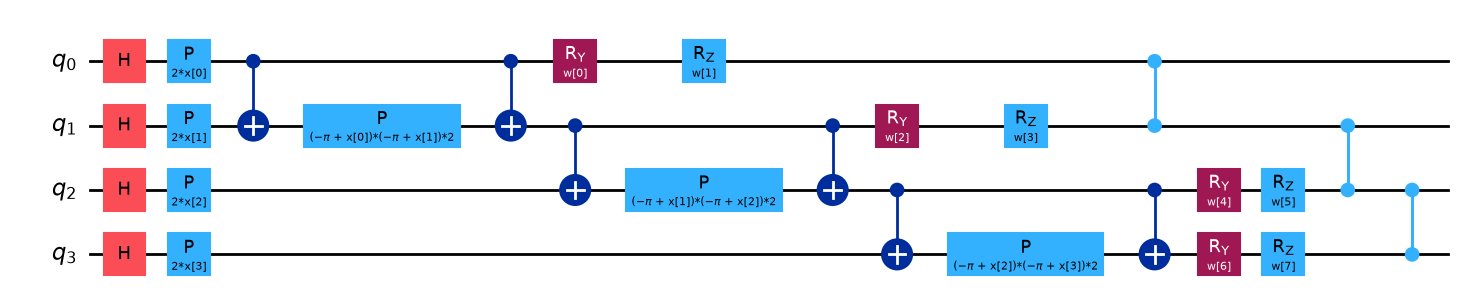

In [11]:
# --- (a) PennyLane overlap kernel vs numpy vs Qiskit's FidelityStatevectorKernel (framework parity, paper Table I: C1/C2 vs C5/C6)
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
def pl_state_fn(q, reps, entanglement="full"):
    dev = qml.device("default.qubit", wires=q)
    pairs = [(i, j) for i in range(q) for j in range(i + 1, q)]
    @qml.qnode(dev)
    def st(x):
        for _ in range(reps):
            for i in range(q):
                qml.Hadamard(wires=i); qml.RZ(2 * x[i], wires=i)
            for i, j in pairs:
                qml.CNOT(wires=[i, j]); qml.RZ(2 * (np.pi - x[i]) * (np.pi - x[j]), wires=j); qml.CNOT(wires=[i, j])
        return qml.state()
    return st

_x = rng.uniform(-np.pi, np.pi, size=(8, 4))
st_fn = pl_state_fn(4, ZZ_REPS)
S_pl = np.array([st_fn(x) for x in _x])
K_pl = np.abs(S_pl.conj() @ S_pl.T) ** 2
K_np = fid_kernel(_x, _x)
K_qk = FidelityStatevectorKernel(feature_map=zz_feature_map(4, reps=ZZ_REPS, entanglement="full")).evaluate(_x)
print("max |K_numpy - K_qiskit-ml| =", float(np.abs(K_np - K_qk).max()), "| max |K_numpy - K_pennylane| =", float(np.abs(K_np - K_pl).max()))

# --- (b) Qiskit EstimatorQNN vs PennyLane forward pass of the same VQC circuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit_machine_learning.neural_networks import EstimatorQNN
def qiskit_vqc(q, L):
    xs, ws = ParameterVector("x", q), ParameterVector("w", L * q * 2)
    fm = zz_feature_map(q, reps=1, entanglement="linear")
    qc = QuantumCircuit(q)
    for l in range(L):
        qc.compose(fm.assign_parameters(dict(zip(fm.parameters, xs))), inplace=True)
        for i in range(q):
            qc.ry(ws[(l * q + i) * 2], i); qc.rz(ws[(l * q + i) * 2 + 1], i)
        for i in range(q - 1): qc.cz(i, i + 1)
    return EstimatorQNN(circuit=qc, input_params=list(xs), weight_params=list(ws), observables=SparsePauliOp("Z" * q)), qc

for qq in QUBITS:
    qnn, qc_vqc = qiskit_vqc(qq, VQC_L)
    xin = rng.uniform(-np.pi, np.pi, size=(5, qq)); win = rng.normal(0, 0.5, size=(VQC_L, qq, 2))
    out_qk = qnn.forward(xin, win.reshape(-1))[:, 0]
    out_pl = make_vqc_circuit(qq, VQC_L)(torch.tensor(xin), torch.tensor(win)).numpy()
    print(f"q={qq}: max |Qiskit EstimatorQNN - PennyLane| = {np.abs(out_qk - out_pl).max():.2e}  (depth of Qiskit circuit {qc_vqc.decompose().depth()})")
display(qiskit_vqc(4, 1)[1].draw("mpl", fold=30))

## 9. Classical baselines on exactly the same inputs

The paper's only classical reference is `C0`, the encoder's own linear head. That is a weak baseline, because the encoder itself is a neural network trained on all features. To see what the *quantum part* contributes we also train
an **RBF-kernel SVC** and a **random forest** on the very same `q` angles that the quantum models receive, and, as a reference for the whole pipeline, a **random forest** (NSL-KDD) or **linear SVM** (Ling-Spam) on all input features.

In [12]:
def classical_baselines(theta_tr, y_tr, theta_sets, X_tr_full, y_tr_full, X_sets_full, seed, dataset):
    """SVC(rbf), RandomForest on the same q angles as the quantum models; RF / LinearSVC on all input features."""
    out = {}
    t = time.time(); svc = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced").fit(theta_tr, y_tr)
    out["SVC-rbf (q angles)"] = ({k: svc.decision_function(v) for k, v in theta_sets.items()}, time.time() - t)
    t = time.time(); rf = RandomForestClassifier(300, class_weight="balanced", random_state=seed, n_jobs=2).fit(theta_tr, y_tr)
    out["RF (q angles)"] = ({k: rf.predict_proba(v)[:, 1] - 0.5 for k, v in theta_sets.items()}, time.time() - t)
    t = time.time()
    if dataset == "lingspam":
        m = LinearSVC(C=1.0, class_weight="balanced", random_state=seed).fit(X_tr_full, y_tr_full)
        out["LinearSVC (all TF-IDF)"] = ({k: m.decision_function(v) for k, v in X_sets_full.items()}, time.time() - t)
    else:
        m = RandomForestClassifier(300, class_weight="balanced", random_state=seed, n_jobs=2).fit(X_tr_full, y_tr_full)
        out["RF (all 121 features)"] = ({k: m.predict_proba(v)[:, 1] - 0.5 for k, v in X_sets_full.items()}, time.time() - t)
    return out

## 10. The main experiment

For every dataset and every seed the loop does: split -> train the encoder -> `C0` -> QSVM with 2 and 4 qubits -> classical baselines on the same angles -> VQC with 2 and 4 qubits (joint training). Scores for validation, test and (NSL-KDD) the in-distribution hold-out are stored in `RESULTS`.
This is the long cell of the notebook (about 5 minutes in FAST mode, about 36 minutes in the full run).

In [13]:
ART = {}      # artefacts of the first seed, reused for figures and the device proxy

def run_dataset(name):
    for si, seed in enumerate(SEEDS):
        t0 = time.time(); print(f"[{name}] seed {seed}")
        sets, meta = PREP[name](seed)
        Xtr, ytr = sets["train"]; Xva, yva = sets["val"]
        # encoder trained on (a subset of) the training split
        sub = strat_sub(ytr, NSL_ENC_N if name == "nslkdd" else None, seed)
        enc, hist = train_encoder(Xtr[sub], ytr[sub], Xva, yva, seed)
        ev_sets = {k: v for k, v in sets.items() if k in ("test", "internal")}
        ylog = {k: v[1] for k, v in ev_sets.items()}
        # ---- C0: classical linear head of the same encoder
        lg_va, E_va = encode(enc, Xva)
        E = {k: encode(enc, v[0]) for k, v in ev_sets.items()}
        record(name, seed, "C0 MLP+linear head", 0, yva, lg_va[:, 1] - lg_va[:, 0], ylog, {k: E[k][0][:, 1] - E[k][0][:, 0] for k in E}, 0.0)
        # ---- QSVM (Qiskit-equivalent exact statevector kernel) on a stratified Gram subset
        kidx = strat_sub(ytr, N_KERNEL_TRAIN[name], seed)
        _, E_tr = encode(enc, Xtr[kidx]); ytr_k = ytr[kidx]
        vidx = strat_sub(yva, N_VAL_EVAL[name], seed)
        for q in QUBITS:
            am = AngleMap().fit(E_tr, q)
            th_tr = am(E_tr); th_va = am(E_va)[vidx]; th_ev = {k: am(E[k][1]) for k in E}
            fitted = {}
            for variant, kw in (("QSVM", {}), ("QSVM-tuned", dict(reps_grid=TUNE_REPS, bw_grid=TUNE_BW))):
                t = time.time(); qs = QSVM(**kw).fit(th_tr, ytr_k, seed=seed)
                s_va = qs.score(th_va); s_ev = {k: qs.score(v) for k, v in th_ev.items()}; dt = time.time() - t
                record(name, seed, f"{variant} q={q}", q, yva[vidx], s_va, ylog, s_ev, dt)
                print(f"  {variant} q={q}: reps={qs.reps}, bw={qs.bw}, C={qs.C}, {dt:.1f}s")
                fitted[variant] = (qs, s_va, s_ev)
            if si == 0 and q == max(QUBITS):
                qs, s_va, s_ev = fitted["QSVM"]; qt, s_va_t, s_ev_t = fitted["QSVM-tuned"]
                ART[name] = dict(theta_tr=th_tr, y_tr=ytr_k, th_ev=th_ev, y_ev=ylog, s_ev=s_ev, s_va=s_va, y_va=yva[vidx], qsvm=qs,
                                 qsvm_tuned=qt, s_ev_tuned=s_ev_t, s_va_tuned=s_va_t,
                                 meta=meta, enc_hist=hist, am=am, K_raw=qs.K_raw)
            if q == max(QUBITS):
                # classical baselines on the same q angles / on all features
                base = classical_baselines(th_tr, ytr_k, {"val": th_va, **th_ev}, Xtr[sub], ytr[sub], {"val": Xva[vidx], **{k: ev_sets[k][0] for k in ev_sets}}, seed, name)
                for mname, (sc, dtb) in base.items():
                    record(name, seed, mname, q, yva[vidx], sc["val"], ylog, {k: sc[k] for k in ev_sets}, dtb)
        # ---- VQC, joint training on a subsample of the training split
        vsub = strat_sub(ytr, N_VQC_TRAIN[name], seed)
        for q in QUBITS:
            t = time.time(); vm, vh = train_vqc(enc, q, Xtr[vsub], ytr[vsub], Xva[vidx], yva[vidx], seed)
            s_va = vqc_scores(vm, Xva[vidx]); s_ev = {k: vqc_scores(vm, ev_sets[k][0]) for k in ev_sets}; dt = time.time() - t
            record(name, seed, f"VQC q={q}", q, yva[vidx], s_va, ylog, s_ev, dt)
            if si == 0:
                ART.setdefault(name + "_vqc", {})[q] = dict(hist=vh, y_ev=ylog, s_ev=s_ev)
        print(f"  seed done in {time.time() - t0:.0f}s")

for ds in DATASETS:
    run_dataset(ds)
df = pd.DataFrame(RESULTS)
print(len(df), "result rows")

[lingspam] seed 42


  encoder: 12 epochs, best val F1 0.9806


  QSVM q=2: reps=2, bw=1.0, C=100.0, 2.5s


  QSVM-tuned q=2: reps=1, bw=0.5, C=1.0, 8.7s


  QSVM q=4: reps=2, bw=1.0, C=1.0, 5.0s


...

  QSVM q=4: reps=2, bw=1.0, C=10.0, 9.3s


  QSVM-tuned q=4: reps=1, bw=0.25, C=1.0, 22.2s


  VQC q=2: 25 epochs, best val loss 0.0150


  VQC q=4: 25 epochs, best val loss 0.0369


  seed done in 402s
180 result rows


## 11. Results tables

Mean +/- standard deviation over seeds. For NSL-KDD we show the official `KDDTest+` split and, separately, the in-distribution hold-out carved from `KDDTrain+` (explained in the critical-reading section).

In [14]:
def summarize(df, dataset, ev="test", thr="tuned", cols=("acc", "f1_macro", "auroc", "auprc")):
    d = df[(df.dataset == dataset) & (df.evalset == ev) & (df.thr == thr)]
    g = d.groupby("model", sort=False)[list(cols)].agg(["mean", "std"])
    out = pd.DataFrame(index=g.index)
    for c in cols:
        out[c] = [f"{m:.4f} ± {0 if np.isnan(s) else s:.4f}" for m, s in zip(g[c]["mean"], g[c]["std"])]
    out["time_s"] = d.groupby("model", sort=False)["seconds"].mean().round(1)
    return out

for ds in DATASETS:
    for ev in (["test", "internal"] if ds == "nslkdd" else ["test"]):
        print(f"\n=== {ds} / {ev} set / threshold tuned on validation (F-beta, beta=2), mean ± std over {N_SEEDS} seeds ===")
        display(summarize(df, ds, ev, "tuned"))
        print(f"--- same, default threshold (decision score = 0) ---")
        display(summarize(df, ds, ev, "default"))


=== lingspam / test set / threshold tuned on validation (F-beta, beta=2), mean ± std over 3 seeds ===


,acc,f1_macro,auroc,auprc,time_s
model,,,,,
C0 MLP+linear head,0.9925 ± 0.0065,0.9867 ± 0.0117,0.9996 ± 0.0005,0.9982 ± 0.0023,0.0
QSVM q=2,0.9419 ± 0.0501,0.9051 ± 0.0734,0.9470 ± 0.0317,0.8459 ± 0.0994,3.0
QSVM-tuned q=2,0.9891 ± 0.0053,0.9806 ± 0.0092,0.9935 ± 0.0046,0.9388 ± 0.0690,12.6
QSVM q=4,0.8797 ± 0.1019,0.8155 ± 0.1430,0.8767 ± 0.1074,0.7157 ± 0.2556,6.3
QSVM-tuned q=4,0.9885 ± 0.0072,0.9792 ± 0.0132,0.9942 ± 0.0094,0.9815 ± 0.0296,23.5
SVC-rbf (q angles),0.9919 ± 0.0072,0.9856 ± 0.0128,0.9986 ± 0.0019,0.9879 ± 0.0182,0.0
RF (q angles),0.9942 ± 0.0061,0.9896 ± 0.0109,0.9964 ± 0.0036,0.9787 ± 0.0187,2.0
LinearSVC (all TF-IDF),0.9960 ± 0.0020,0.9927 ± 0.0036,0.9999 ± 0.0001,0.9993 ± 0.0006,0.1
VQC q=2,0.9868 ± 0.0036,0.9765 ± 0.0059,0.9997 ± 0.0003,0.9985 ± 0.0013,38.3


--- same, default threshold (decision score = 0) ---


,acc,f1_macro,auroc,auprc,time_s
model,,,,,
C0 MLP+linear head,0.9954 ± 0.0043,0.9918 ± 0.0078,0.9996 ± 0.0005,0.9982 ± 0.0023,0.0
QSVM q=2,0.9303 ± 0.0535,0.8895 ± 0.0733,0.9470 ± 0.0317,0.8459 ± 0.0994,3.0
QSVM-tuned q=2,0.9873 ± 0.0065,0.9778 ± 0.0113,0.9935 ± 0.0046,0.9388 ± 0.0690,12.6
QSVM q=4,0.8895 ± 0.0942,0.8205 ± 0.1423,0.8767 ± 0.1074,0.7157 ± 0.2556,6.3
QSVM-tuned q=4,0.9902 ± 0.0082,0.9826 ± 0.0144,0.9942 ± 0.0094,0.9815 ± 0.0296,23.5
SVC-rbf (q angles),0.9942 ± 0.0061,0.9898 ± 0.0107,0.9986 ± 0.0019,0.9879 ± 0.0182,0.0
RF (q angles),0.9948 ± 0.0052,0.9907 ± 0.0092,0.9964 ± 0.0036,0.9787 ± 0.0187,2.0
LinearSVC (all TF-IDF),0.9902 ± 0.0026,0.9819 ± 0.0049,0.9999 ± 0.0001,0.9993 ± 0.0006,0.1
VQC q=2,0.9937 ± 0.0056,0.9886 ± 0.0100,0.9997 ± 0.0003,0.9985 ± 0.0013,38.3



=== nslkdd / test set / threshold tuned on validation (F-beta, beta=2), mean ± std over 3 seeds ===


...

,acc,f1_macro,auroc,auprc,time_s
model,,,,,
C0 MLP+linear head,0.7942 ± 0.0065,0.7939 ± 0.0065,0.9321 ± 0.0063,0.9464 ± 0.0026,0.0
QSVM q=2,0.7462 ± 0.0248,0.7452 ± 0.0257,0.8209 ± 0.0550,0.8630 ± 0.0366,17.2
QSVM-tuned q=2,0.7969 ± 0.0071,0.7966 ± 0.0072,0.8204 ± 0.0821,0.8831 ± 0.0311,37.5
QSVM q=4,0.7661 ± 0.0217,0.7657 ± 0.0221,0.8565 ± 0.0256,0.8921 ± 0.0021,14.1
QSVM-tuned q=4,0.7934 ± 0.0130,0.7931 ± 0.0132,0.8412 ± 0.0424,0.8973 ± 0.0127,32.5
SVC-rbf (q angles),0.7984 ± 0.0132,0.7983 ± 0.0132,0.7567 ± 0.0222,0.8596 ± 0.0086,0.3
RF (q angles),0.7925 ± 0.0167,0.7923 ± 0.0167,0.8458 ± 0.0108,0.8641 ± 0.0104,2.4
RF (all 121 features),0.7752 ± 0.0077,0.7743 ± 0.0079,0.9616 ± 0.0008,0.9645 ± 0.0008,64.3
VQC q=2,0.7814 ± 0.0104,0.7809 ± 0.0110,0.9046 ± 0.0271,0.9307 ± 0.0151,76.0



=== nslkdd / internal set / threshold tuned on validation (F-beta, beta=2), mean ± std over 3 seeds ===


,acc,f1_macro,auroc,auprc,time_s
model,,,,,
C0 MLP+linear head,0.9951 ± 0.0004,0.9951 ± 0.0004,0.9999 ± 0.0000,0.9999 ± 0.0000,0.0
QSVM q=2,0.7895 ± 0.2671,0.7463 ± 0.3415,0.9299 ± 0.0823,0.9151 ± 0.1089,17.2
QSVM-tuned q=2,0.9945 ± 0.0022,0.9945 ± 0.0022,0.9980 ± 0.0019,0.9962 ± 0.0028,37.5
QSVM q=4,0.9439 ± 0.0167,0.9438 ± 0.0167,0.9852 ± 0.0063,0.9824 ± 0.0046,14.1
QSVM-tuned q=4,0.9933 ± 0.0033,0.9933 ± 0.0033,0.9986 ± 0.0010,0.9975 ± 0.0011,32.5
SVC-rbf (q angles),0.9952 ± 0.0010,0.9952 ± 0.0010,0.9982 ± 0.0003,0.9965 ± 0.0019,0.3
RF (q angles),0.9947 ± 0.0015,0.9947 ± 0.0016,0.9995 ± 0.0002,0.9992 ± 0.0003,2.4
RF (all 121 features),0.9979 ± 0.0009,0.9979 ± 0.0009,1.0000 ± 0.0000,1.0000 ± 0.0000,64.3
VQC q=2,0.9939 ± 0.0008,0.9939 ± 0.0008,0.9997 ± 0.0001,0.9997 ± 0.0001,76.0


--- same, default threshold (decision score = 0) ---


,acc,f1_macro,auroc,auprc,time_s
model,,,,,
C0 MLP+linear head,0.9964 ± 0.0004,0.9964 ± 0.0004,0.9999 ± 0.0000,0.9999 ± 0.0000,0.0
QSVM q=2,0.9046 ± 0.0731,0.9035 ± 0.0742,0.9299 ± 0.0823,0.9151 ± 0.1089,17.2
QSVM-tuned q=2,0.9954 ± 0.0011,0.9954 ± 0.0011,0.9980 ± 0.0019,0.9962 ± 0.0028,37.5
QSVM q=4,0.9556 ± 0.0144,0.9554 ± 0.0145,0.9852 ± 0.0063,0.9824 ± 0.0046,14.1
QSVM-tuned q=4,0.9954 ± 0.0004,0.9954 ± 0.0004,0.9986 ± 0.0010,0.9975 ± 0.0011,32.5
SVC-rbf (q angles),0.9956 ± 0.0009,0.9956 ± 0.0009,0.9982 ± 0.0003,0.9965 ± 0.0019,0.3
RF (q angles),0.9955 ± 0.0006,0.9955 ± 0.0006,0.9995 ± 0.0002,0.9992 ± 0.0003,2.4
RF (all 121 features),0.9989 ± 0.0002,0.9989 ± 0.0002,1.0000 ± 0.0000,1.0000 ± 0.0000,64.3
VQC q=2,0.9945 ± 0.0006,0.9945 ± 0.0006,0.9997 ± 0.0001,0.9997 ± 0.0001,76.0


## 12. Figures

Encoder training curves, the Gram matrix of the 4-qubit kernel with samples sorted by class (a good kernel shows a block structure: high similarity inside a class), confusion matrices of the 4-qubit QSVM (attack/spam is the positive class) and the VQC loss curves.

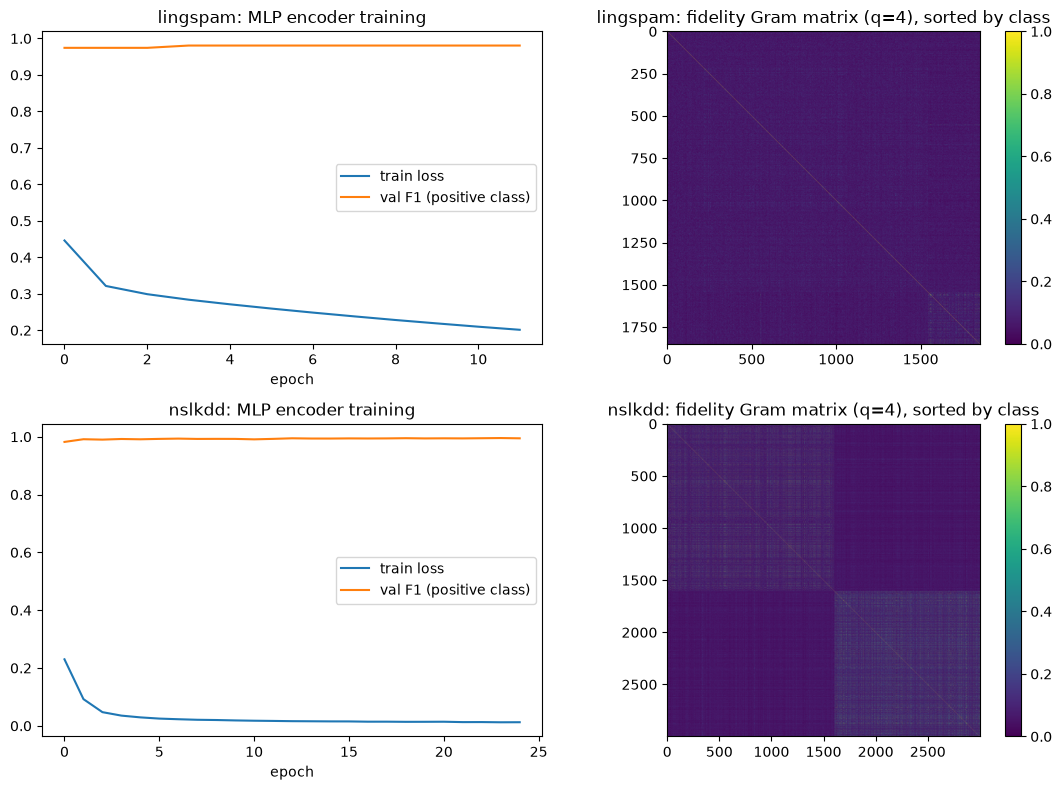

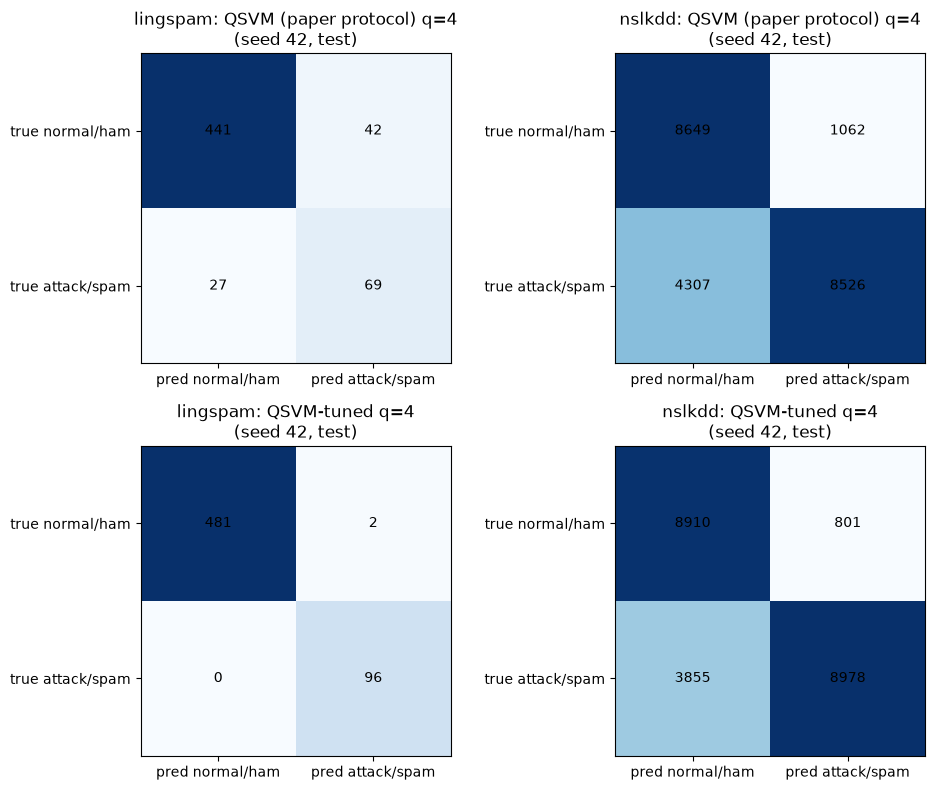

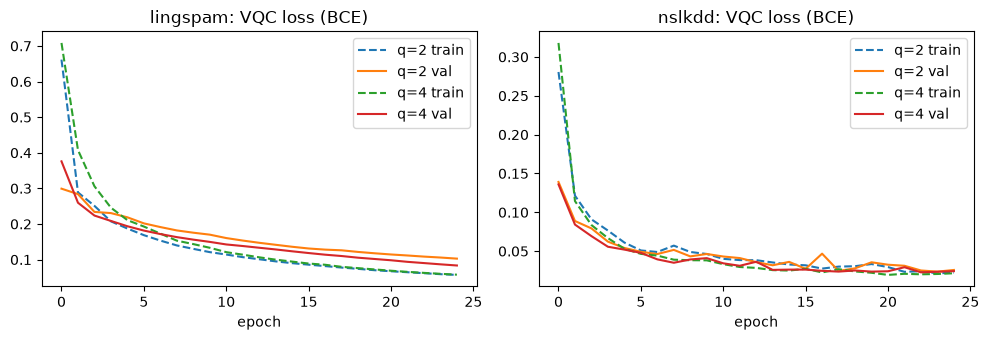

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for r, ds in enumerate(DATASETS):
    a = ART[ds]
    ax = axes[r, 0]
    h = np.array(a["enc_hist"]); ax.plot(h[:, 0], label="train loss"); ax.plot(h[:, 1], label="val F1 (positive class)")
    ax.set_title(f"{ds}: MLP encoder training"); ax.set_xlabel("epoch"); ax.legend()
    ax = axes[r, 1]
    order = np.argsort(a["y_tr"], kind="stable")
    Ks = a["K_raw"][np.ix_(order, order)]
    im = ax.imshow(Ks, cmap="viridis", vmin=0, vmax=1); ax.set_title(f"{ds}: fidelity Gram matrix (q={max(QUBITS)}), sorted by class")
    plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for r, (tag, sk, vk) in enumerate((("QSVM (paper protocol)", "s_ev", "s_va"), ("QSVM-tuned", "s_ev_tuned", "s_va_tuned"))):
    for ax, ds in zip(axes[r], DATASETS):
        a = ART[ds]; thr = best_threshold(a["y_va"], a[vk])
        cm = confusion_matrix(a["y_ev"]["test"], (a[sk]["test"] >= thr).astype(int), labels=[0, 1])
        ax.imshow(cm, cmap="Blues")
        for (i, j), v in np.ndenumerate(cm): ax.text(j, i, v, ha="center", va="center", color="black")
        ax.set_xticks([0, 1], ["pred normal/ham", "pred attack/spam"]); ax.set_yticks([0, 1], ["true normal/ham", "true attack/spam"])
        ax.set_title(f"{ds}: {tag} q={max(QUBITS)}\n(seed {SEEDS[0]}, test)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, ds in zip(axes, DATASETS):
    for q, d in ART[ds + "_vqc"].items():
        h = np.array(d["hist"]); ax.plot(h[:, 0], "--", label=f"q={q} train"); ax.plot(h[:, 1], label=f"q={q} val")
    ax.set_title(f"{ds}: VQC loss (BCE)"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

## 13. From simulator to a (modelled) quantum device

On hardware the kernel entry `k(x, y)` is *measured*: run the circuit `U(y)^dagger U(x)` on `|0...0>` and count how often the outcome is `0000`; that fraction estimates `|<phi(y)|phi(x)>|^2`. With 1024 shots the estimate has a standard error of up to 0.016, and gate and readout errors bias it further.
Following the paper (Section VII-H) we take a small **reference set** of training points (64 in the paper) and a **small test subset** (about 100; for NSL-KDD every attack sub-type appears at least once), measure all needed kernel entries, centre them with the training statistics, and classify with the SVM.

We have no quantum computer here, so the cell uses `AerSimulator.from_backend(FakeTorino())`, a noise model built from the calibration data of IBM Torino (gate errors, relaxation, readout errors), and the circuit is transpiled to Torino's native gates and connectivity.
We compare five versions on the same samples: exact statevector kernel (no noise), shots only, noisy device model, noisy + our readout mitigation (a tensored confusion-matrix inversion, a simpler cousin of the paper's M3), and the paper's hardware numbers. Dynamical decoupling is not modelled.
**These are simulated device results; they say nothing certain about what the real chip would give.**

In [16]:
from qiskit import transpile
from qiskit.circuit import Parameter
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeTorino

fake = FakeTorino()
noisy_sim = AerSimulator.from_backend(fake)
ideal_sim = AerSimulator()
print("noise model basis gates:", noisy_sim.configuration().basis_gates[:8], "...")

def kernel_circuit(q, reps=ZZ_REPS):
    """compute-uncompute circuit U(y)^dagger U(x) |0>, measured in the Z basis (paper Section VII-H)."""
    xs, ys = ParameterVector("x", q), ParameterVector("y", q)
    fm = zz_feature_map(q, reps=reps, entanglement="full")
    qc = QuantumCircuit(q)
    qc.compose(fm.assign_parameters(dict(zip(fm.parameters, xs))), inplace=True)
    qc.compose(fm.assign_parameters(dict(zip(fm.parameters, ys))).inverse(), inplace=True)
    qc.measure_all()
    return qc, xs, ys

def readout_calibration(sim, q, layout_circuit_t):
    """Tensored readout calibration from the all-0 and all-1 preparations (per-qubit confusion matrices)."""
    cal = []
    for state in (0, 1):
        c = QuantumCircuit(q)
        if state: c.x(range(q))
        c.measure_all()
        ct = transpile(c, sim, initial_layout=layout_circuit_t, optimization_level=0, seed_transpiler=SEED)
        cal.append(sim.run(ct, shots=SHOTS * 8, seed_simulator=SEED).result().get_counts())
    p10 = np.zeros(q); p01 = np.zeros(q)       # P(read 1 | prep 0), P(read 0 | prep 1) per qubit
    for bits, n in cal[0].items():
        for i, b in enumerate(reversed(bits)): p10[i] += n * (b == "1") / (SHOTS * 8)
    for bits, n in cal[1].items():
        for i, b in enumerate(reversed(bits)): p01[i] += n * (b == "0") / (SHOTS * 8)
    return p10, p01

def mitigated_p0(counts, p10, p01):
    """Probability of the all-zero outcome after inverting the tensored readout confusion matrix."""
    q = len(p10)
    shots = sum(counts.values())
    vec = np.zeros(2 ** q)
    for bits, n in counts.items(): vec[int(bits.replace(" ", ""), 2)] += n / shots
    Minv = np.array([[1.0]])
    for i in reversed(range(q)):                                   # qubit 0 is the least-significant bit
        M = np.array([[1 - p10[i], p01[i]], [p10[i], 1 - p01[i]]])
        Minv = np.kron(Minv, np.linalg.inv(M))
    corr = np.clip(Minv @ vec, 0, None); corr /= corr.sum()
    return corr[0]

def run_kernel_pairs(sim, qc_t, xs, ys, X, Y, shots, seed, p_cal=None):
    """Estimate K(X[i], Y[i]) for matched rows by running the bound circuits; returns (raw p0, mitigated p0)."""
    binds = {}
    for k, p in enumerate(xs): binds[p] = list(X[:, k])
    for k, p in enumerate(ys): binds[p] = list(Y[:, k])
    res = sim.run(qc_t, parameter_binds=[binds], shots=shots, seed_simulator=seed).result()
    raw, mit = [], []
    for i in range(len(X)):
        c = res.get_counts(i)
        raw.append(c.get("0" * len(xs), 0) / shots)
        mit.append(mitigated_p0(c, *p_cal) if p_cal is not None else np.nan)
    return np.array(raw), np.array(mit)

def hw_subset(name, n, seed):
    """Stratified subset of the test split; for NSL-KDD every attack sub-type is included at least once (paper Section VII-H)."""
    y = ART[name]["y_ev"]["test"]; idx = np.arange(len(y)); g = np.random.default_rng(seed)
    chosen = []
    if name == "nslkdd" and HW_ALL_SUBTYPES:
        types = ART[name]["meta"]["test_attack_type"]
        for t in np.unique(types):
            chosen.append(g.choice(np.where(types == t)[0]))
    rest = np.setdiff1d(idx, chosen)
    need = max(n - len(chosen), 0)
    take = rest[np.sort(strat_sub(y[rest], min(need, len(rest)), seed))] if need > 0 else np.array([], int)
    return np.sort(np.concatenate([np.array(chosen, int), take]))

def oof_threshold(Ktr, y, C, folds=4, seed=SEED):
    """Decision threshold from out-of-fold scores on the small reference set (there is no validation set on the device)."""
    s = np.zeros(len(y))
    for a_, b_ in StratifiedKFold(folds, shuffle=True, random_state=seed).split(Ktr, y):
        Kc, col, tot = center_train(Ktr[np.ix_(a_, a_)])
        m = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(Kc, y[a_])
        s[b_] = m.decision_function(center_test(Ktr[np.ix_(b_, a_)], col, tot))
    return best_threshold(y, s)

def device_experiment(name, q=max(QUBITS)):
    a = ART[name]; seed = SEEDS[0]
    sel = hw_subset(name, HW_N_TEST, seed)
    qt = a["qsvm_tuned"]; reps, bw = qt.reps, qt.bw           # the (reps, angle scale, C) chosen by cross-validation for the tuned QSVM
    th_te, y_te = bw * a["th_ev"]["test"][sel], a["y_ev"]["test"][sel]
    g = np.random.default_rng(seed)    # class-balanced reference set (half normal/ham, half attack/spam)
    ridx = np.sort(np.concatenate([g.choice(np.where(a["y_tr"] == c)[0], HW_N_REF // 2, replace=False) for c in (0, 1)]))
    th_ref, y_ref = bw * a["theta_tr"][ridx], a["y_tr"][ridx]
    qc, xs, ys = kernel_circuit(q, reps)
    qc_noisy = transpile(qc, noisy_sim, optimization_level=3, seed_transpiler=SEED)      # layout/routing chosen by the transpiler (low-error qubits)
    layout = list(qc_noisy.layout.final_index_layout(filter_ancillas=True))               # physical qubit that is read out for virtual qubit i
    qc_ideal = transpile(qc, ideal_sim, optimization_level=0, seed_transpiler=SEED)
    print(f"{name}: QSVM-tuned settings reps={reps}, angle scale={bw}, C={qt.C}; transpiled kernel circuit: depth {qc_noisy.depth()}, 2q gates {qc_noisy.count_ops().get('cz', qc_noisy.count_ops().get('ecr', 0))}, test samples {len(sel)} ({int(y_te.sum())} positive), reference set {len(ridx)}")
    p_cal = readout_calibration(noisy_sim, q, layout)
    print("  readout error per qubit  P(1|0):", np.round(p_cal[0], 4), " P(0|1):", np.round(p_cal[1], 4))
    iu = np.triu_indices(len(ridx), 1)
    rows_i, rows_j = np.repeat(np.arange(len(sel)), len(ridx)), np.tile(np.arange(len(ridx)), len(sel))
    variants = {}
    for vname, sim, qct in (("shots only", ideal_sim, qc_ideal), ("noisy device model", noisy_sim, qc_noisy)):
        t = time.time()
        raw_tr, mit_tr = run_kernel_pairs(sim, qct, xs, ys, th_ref[iu[0]], th_ref[iu[1]], SHOTS, SEED, p_cal if sim is noisy_sim else None)
        raw_te, mit_te = run_kernel_pairs(sim, qct, xs, ys, th_te[rows_i], th_ref[rows_j], SHOTS, SEED + 1, p_cal if sim is noisy_sim else None)
        variants[vname] = (raw_tr, raw_te)
        if sim is noisy_sim: variants["noisy + readout mitigation"] = (mit_tr, mit_te)
        print(f"  {vname}: {time.time() - t:.0f}s")
    exact_tr = fid_kernel(th_ref, th_ref, reps)
    exact_te = fid_kernel(th_te, th_ref, reps)
    variants = {"exact statevector (same ref set)": (exact_tr[iu], exact_te.ravel()), **variants}
    out = []
    for vname, (ktr_vec, kte_vec) in variants.items():
        Ktr = np.eye(len(ridx)); Ktr[iu] = ktr_vec; Ktr = np.triu(Ktr) + np.triu(Ktr, 1).T
        Kte = kte_vec.reshape(len(sel), len(ridx))
        Kc, col, tot = center_train(Ktr)
        svc = SVC(kernel="precomputed", C=qt.C, class_weight="balanced").fit(Kc, y_ref)
        s = svc.decision_function(center_test(Kte, col, tot))
        thr = oof_threshold(Ktr, y_ref, qt.C)        # F-beta threshold from out-of-fold scores on the reference set
        r = metric_row(y_te, s, thr) if len(np.unique(y_te)) == 2 else {}
        out.append(dict(dataset=name, variant=vname, n_test=len(sel), mean_abs_kernel_err=float(np.abs(kte_vec - exact_te.ravel()).mean()), **{k: r.get(k) for k in ("acc", "f1_macro", "auroc", "auprc")}))
    return pd.DataFrame(out)

DEV = pd.concat([device_experiment(ds) for ds in DATASETS], ignore_index=True)
display(DEV.round(4))

noise model basis gates: ['cz', 'id', 'rz', 'sx', 'x', 'break_loop', 'continue_loop', 'delay'] ...


lingspam: QSVM-tuned settings reps=1, angle scale=0.25, C=0.1; transpiled kernel circuit: depth 129, 2q gates 38, test samples 100 (17 positive), reference set 64


  readout error per qubit  P(1|0): [0.0078 0.0096 0.021  0.0232]  P(0|1): [0.0085 0.0077 0.0171 0.022 ]


  shots only: 35s


  noisy device model: 246s


nslkdd: QSVM-tuned settings reps=1, angle scale=0.25, C=1.0; transpiled kernel circuit: depth 129, 2q gates 38, test samples 100 (72 positive), reference set 64


  readout error per qubit  P(1|0): [0.0078 0.0096 0.021  0.0232]  P(0|1): [0.0085 0.0077 0.0171 0.022 ]


  shots only: 47s


  noisy device model: 229s


,dataset,variant,n_test,mean_abs_kernel_err,acc,f1_macro,auroc,auprc
0,lingspam,exact statevector (same ref set),100,0.0000,0.89,0.8423,0.9922,0.9673
1,lingspam,shots only,100,0.0081,0.88,0.8306,0.9908,0.9631
2,lingspam,noisy device model,100,0.0347,0.88,0.8306,0.9887,0.9538
3,lingspam,noisy + readout mitigation,100,0.0253,0.89,0.8423,0.9894,0.9570
4,nslkdd,exact statevector (same ref set),100,0.0000,0.85,0.8291,0.9077,0.9420
5,nslkdd,shots only,100,0.0082,0.81,0.7898,0.9102,0.9534
6,nslkdd,noisy device model,100,0.0454,0.80,0.7802,0.9147,0.9529
7,nslkdd,noisy + readout mitigation,100,0.0332,0.81,0.7898,0.9112,0.9540


### Real IBM hardware (optional)

If you have an IBM Quantum account, put your API token in `IBM_TOKEN` in the configuration cell. The cell below then connects to the backend; exercise 5 asks you to run the kernel circuits of the previous cell through `SamplerV2`. Without a token it is skipped, as are all hardware claims below.

In [17]:
if IBM_TOKEN:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    backend = service.backend(IBM_BACKEND)
    print("running on", backend.name, "- reuse the circuits of the previous cell with SamplerV2(mode=backend); see exercise 5")
else:
    print("IBM_TOKEN is empty: the real-hardware cell is skipped (the noisy FakeTorino model above is a proxy, not a device).")

IBM_TOKEN is empty: the real-hardware cell is skipped (the noisy FakeTorino model above is a proxy, not a device).


## 14. Paper vs this notebook

Each number of the paper's Tables III and IV is compared with our mean over seeds on the **test** split with the paper's tuned-threshold protocol. Verdict rule: within **0.02** absolute = *reproduced*; more than 0.02 above the paper = *exceeded*; more than 0.02 below = *not reached*.
Paper `C0 ... C4` map to: `C0 MLP+linear head`, `C1` QSVM q=2, `C2` QSVM q=4, `C3` VQC q=2, `C4` VQC q=4 (our reading of the tables, see "The paper in one page"). Rows `C5 ... C9` of the paper are exact copies and are not repeated.

In [18]:
PAPER = {  # Tables III-IV of the paper: (Acc, F1 macro, AUROC, AUPRC). C5-C9 repeat C0-C4 exactly in the paper.
    "nslkdd": {"C0 MLP+linear head": (0.6613, 0.6911, 0.7411, 0.7032), "QSVM q=2": (0.8410, 0.8322, 0.8802, 0.9057),
               "QSVM q=4": (0.9098, 0.9212, 0.9335, 0.9407), "VQC q=2": (0.8410, 0.8522, 0.8899, 0.9289), "VQC q=4": (0.8073, 0.7907, 0.9365, 0.9402)},
    "lingspam": {"C0 MLP+linear head": (0.9001, 0.9212, 0.9504, 0.9103), "QSVM q=2": (0.9884, 0.9710, 0.9990, 0.9768),
                 "QSVM q=4": (0.9996, 0.9987, 1.0000, 1.0000), "VQC q=2": (0.9788, 0.9812, 0.9997, 0.9894), "VQC q=4": (0.9552, 0.9856, 0.9995, 0.9985)}}
for _ds in PAPER:   # the extra QSVM-tuned variant is judged against the same paper rows C1 / C2
    PAPER[_ds]["QSVM-tuned q=2"], PAPER[_ds]["QSVM-tuned q=4"] = PAPER[_ds]["QSVM q=2"], PAPER[_ds]["QSVM q=4"]
PAPER_HW = {"nslkdd": (0.8400, 0.8242, 0.8924, 0.9602), "lingspam": (0.9901, 0.9825, 0.9990, 0.9768)}   # Table V
MET = ("acc", "f1_macro", "auroc", "auprc"); TOL = 0.02

def verdict(p, n):
    d = n - p
    return "reproduced" if abs(d) <= TOL else ("exceeded" if d > 0 else "not reached")

def compare(evalset):
    rows = []
    for ds in DATASETS:
        if evalset not in set(df[df.dataset == ds].evalset): continue
        d = df[(df.dataset == ds) & (df.evalset == evalset) & (df.thr == "tuned")].groupby("model")[list(MET)].mean()
        for model, pv in PAPER[ds].items():
            for m, p in zip(MET, pv):
                n = float(d.loc[model, m])
                rows.append(dict(dataset=ds, config=model, metric=m, paper=p, notebook=round(n, 4), gap=round(n - p, 4), verdict=verdict(p, n)))
    return pd.DataFrame(rows)

cmp_df = compare("test")
print("Numbers: paper | notebook (test split, tuned threshold, mean over seeds) | gap")
display(cmp_df.pivot_table(index=["dataset", "config"], columns="metric", values="gap", aggfunc="first", sort=False)[list(MET)])
print("Verdicts (reproduced = within 0.02):")
display(cmp_df.pivot_table(index=["dataset", "config"], columns="metric", values="verdict", aggfunc="first", sort=False)[list(MET)])
print(cmp_df.groupby(["dataset", "verdict"]).size().unstack(fill_value=0))

# Which NSL-KDD split could the paper's numbers come from? Same comparison against the in-distribution hold-out of KDDTrain+.
cmp_int = compare("internal")
print("\nNSL-KDD: paper numbers vs the IN-DISTRIBUTION hold-out of KDDTrain+ (gap = notebook - paper):")
display(cmp_int.pivot_table(index=["dataset", "config"], columns="metric", values="gap", aggfunc="first", sort=False)[list(MET)])

# ---- claim-level verdicts
def mean_of(ds, model, m, ev="test", thr="tuned"):
    return float(df[(df.dataset == ds) & (df.model == model) & (df.evalset == ev) & (df.thr == thr)][m].mean())

claims = []
for ds in DATASETS:
    c0 = mean_of(ds, "C0 MLP+linear head", "f1_macro")
    vq = {q: mean_of(ds, f"VQC q={q}", "f1_macro") for q in QUBITS}
    base = {m: mean_of(ds, m, "f1_macro") for m in df[(df.dataset == ds)].model.unique() if m.startswith(("SVC", "RF", "LinearSVC"))}
    best_name = max(base, key=base.get)
    for variant in ("QSVM", "QSVM-tuned"):
        qs2, qs4 = mean_of(ds, f"{variant} q=2", "f1_macro"), mean_of(ds, f"{variant} q=4", "f1_macro")
        allq = [qs2, qs4, *vq.values()]
        claims += [
            (ds, variant, "q=4 QSVM has the best macro-F1 of the four quantum heads", max(allq) == qs4, f"QSVM2 {qs2:.3f}, QSVM4 {qs4:.3f}, VQC2 {vq[2]:.3f}, VQC4 {vq[4]:.3f}"),
            (ds, variant, "more qubits help the QSVM (q=4 >= q=2 - 0.005)", qs4 >= qs2 - 0.005, f"{qs4:.3f} vs {qs2:.3f}"),
            (ds, variant, "a quantum head beats the classical linear head C0", max(allq) > c0, f"best quantum {max(allq):.3f} vs C0 {c0:.3f}"),
            (ds, variant, "QSVM matches tuned classical models on the same inputs (within 0.02 macro-F1)", max(qs2, qs4) >= base[best_name] - TOL,
             f"best {variant} {max(qs2, qs4):.3f} vs best classical baseline {base[best_name]:.3f} ({best_name})")]
cl = pd.DataFrame(claims, columns=["dataset", "QSVM variant", "claim", "holds_here", "numbers (macro-F1, tuned threshold)"])
display(cl)

Numbers: paper | notebook (test split, tuned threshold, mean over seeds) | gap


metric                          acc  f1_macro   auroc   auprc
dataset  config                                              
lingspam C0 MLP+linear head  0.0924    0.0655  0.0492  0.0879
         QSVM q=2           -0.0465   -0.0659 -0.0520 -0.1309
         QSVM q=4           -0.1199   -0.1832 -0.1233 -0.2843
         VQC q=2             0.0080   -0.0047 -0.0000  0.0091
         VQC q=4             0.0367   -0.0000  0.0004  0.0009
         QSVM-tuned q=2      0.0007    0.0096 -0.0055 -0.0380
         QSVM-tuned q=4     -0.0111   -0.0195 -0.0058 -0.0185
nslkdd   C0 MLP+linear head  0.1422    0.1123  0.1910  0.2432
         QSVM q=2           -0.1381   -0.1895 -0.0593 -0.0427
         QSVM q=4           -0.1233   -0.1347 -0.0770 -0.0486
         VQC q=2            -0.0582   -0.0698  0.0147  0.0018
         VQC q=4            -0.0058    0.0108 -0.0188 -0.0042
         QSVM-tuned q=2     -0.0463   -0.0376 -0.0598 -0.0226
         QSVM-tuned q=4     -0.1108   -0.1223 -0.0923 -0.0434

Verdicts (reproduced = within 0.02):


metric                               acc     f1_macro        auroc  \
dataset  config                                                      
lingspam C0 MLP+linear head     exceeded     exceeded     exceeded   
         QSVM q=2            not reached  not reached  not reached   
         QSVM q=4            not reached  not reached  not reached   
         VQC q=2              reproduced   reproduced   reproduced   
         VQC q=4                exceeded   reproduced   reproduced   
         QSVM-tuned q=2       reproduced   reproduced   reproduced   
         QSVM-tuned q=4       reproduced   reproduced   reproduced   
nslkdd   C0 MLP+linear head     exceeded     exceeded     exceeded   
         QSVM q=2            not reached  not reached  not reached   
         QSVM q=4            not reached  not reached  not reached   
         VQC q=2             not reached  not reached   reproduced   
         VQC q=4              reproduced   reproduced   reproduced   
         QSVM-tuned q=2      not reached  not reached  not reached   
         QSVM-tuned q=4      not reached  not reached  not reached   

metric                             auprc  
dataset  config                           
lingspam C0 MLP+linear head     exceeded  
         QSVM q=2            not reached  
         QSVM q=4            not reached  
         VQC q=2              reproduced  
         VQC q=4              reproduced  
         QSVM-tuned q=2      not reached  
         QSVM-tuned q=4       reproduced  
nslkdd   C0 MLP+linear head     exceeded  
         QSVM q=2            not reached  
         QSVM q=4            not reached  
         VQC q=2              reproduced  
         VQC q=4              reproduced  
         QSVM-tuned q=2      not reached  
         QSVM-tuned q=4      not reached

verdict   exceeded  not reached  reproduced
dataset                                    
lingspam         5            9          14
nslkdd           4           18           6

NSL-KDD: paper numbers vs the IN-DISTRIBUTION hold-out of KDDTrain+ (gap = notebook - paper):


metric                         acc  f1_macro   auroc   auprc
dataset config                                              
nslkdd  C0 MLP+linear head  0.3338    0.3040  0.2588  0.2967
        QSVM q=2           -0.0515   -0.0859  0.0497  0.0094
        QSVM q=4            0.0341    0.0226  0.0517  0.0417
        VQC q=2             0.1529    0.1417  0.1098  0.0708
        VQC q=4             0.1827    0.1993  0.0631  0.0594
        QSVM-tuned q=2      0.1535    0.1623  0.1178  0.0905
        QSVM-tuned q=4      0.0835    0.0721  0.0651  0.0568

,dataset,QSVM variant,claim,holds_here,"numbers (macro-F1, tuned threshold)"
0,lingspam,QSVM,q=4 QSVM has the best macro-F1 of the four qua...,False,"QSVM2 0.905, QSVM4 0.816, VQC2 0.976, VQC4 0.986"
1,lingspam,QSVM,more qubits help the QSVM (q=4 >= q=2 - 0.005),False,0.816 vs 0.905
2,lingspam,QSVM,a quantum head beats the classical linear head C0,False,best quantum 0.986 vs C0 0.987
3,lingspam,QSVM,QSVM matches tuned classical models on the sam...,False,best QSVM 0.905 vs best classical baseline 0.9...
4,lingspam,QSVM-tuned,q=4 QSVM has the best macro-F1 of the four qua...,False,"QSVM2 0.981, QSVM4 0.979, VQC2 0.976, VQC4 0.986"
5,lingspam,QSVM-tuned,more qubits help the QSVM (q=4 >= q=2 - 0.005),True,0.979 vs 0.981
6,lingspam,QSVM-tuned,a quantum head beats the classical linear head C0,False,best quantum 0.986 vs C0 0.987
7,lingspam,QSVM-tuned,QSVM matches tuned classical models on the sam...,True,best QSVM-tuned 0.981 vs best classical baseli...
8,nslkdd,QSVM,q=4 QSVM has the best macro-F1 of the four qua...,False,"QSVM2 0.643, QSVM4 0.786, VQC2 0.782, VQC4 0.801"
9,nslkdd,QSVM,more qubits help the QSVM (q=4 >= q=2 - 0.005),True,0.786 vs 0.643


### Hardware claim (Table V)

The paper's hardware run is compared with the *noisy device model* of section 13 (not with a real device). With only a few dozen test samples (positives are rare in the Ling-Spam subset), AUROC/AUPRC and even accuracy have a large sampling error, so differences of a few points are not meaningful.

In [19]:
hw = []
for ds in DATASETS:
    p = PAPER_HW[ds]
    hw.append(dict(dataset=ds, source="paper Table V: IBM hardware, ~100 samples", **dict(zip(MET, p))))
    for vname in ("exact statevector (same ref set)", "shots only", "noisy device model", "noisy + readout mitigation"):
        r = DEV[(DEV.dataset == ds) & (DEV.variant == vname)].iloc[0]
        hw.append(dict(dataset=ds, source=f"notebook: {vname} ({int(r.n_test)} samples)", **{m: r[m] for m in MET}))
display(pd.DataFrame(hw).round(4))

,dataset,source,acc,f1_macro,auroc,auprc
0,lingspam,"paper Table V: IBM hardware, ~100 samples",0.9901,0.9825,0.9990,0.9768
1,lingspam,notebook: exact statevector (same ref set) (10...,0.8900,0.8423,0.9922,0.9673
2,lingspam,notebook: shots only (100 samples),0.8800,0.8306,0.9908,0.9631
3,lingspam,notebook: noisy device model (100 samples),0.8800,0.8306,0.9887,0.9538
4,lingspam,notebook: noisy + readout mitigation (100 samp...,0.8900,0.8423,0.9894,0.9570
5,nslkdd,"paper Table V: IBM hardware, ~100 samples",0.8400,0.8242,0.8924,0.9602
6,nslkdd,notebook: exact statevector (same ref set) (10...,0.8500,0.8291,0.9077,0.9420
7,nslkdd,notebook: shots only (100 samples),0.8100,0.7898,0.9102,0.9534
8,nslkdd,notebook: noisy device model (100 samples),0.8000,0.7802,0.9147,0.9529
9,nslkdd,notebook: noisy + readout mitigation (100 samp...,0.8100,0.7898,0.9112,0.9540


## What we found (full run, `FAST_MODE = False`, 3 seeds)

All numbers: macro-F1 on the test split with the paper's tuned-threshold protocol, mean over 3 seeds (see the tables above for the other metrics and standard deviations).

| | C0 linear head | QSVM q=2 | QSVM q=4 | QSVM-tuned q=2 | QSVM-tuned q=4 | VQC q=2 | VQC q=4 | RBF-SVC (q angles) | forest / linear SVM on all features |
|---|---|---|---|---|---|---|---|---|---|
| **Ling-Spam** ours | 0.987 | 0.905 | 0.816 | 0.981 | 0.979 | 0.976 | 0.986 | 0.986 | 0.993 (linear SVM) |
| Ling-Spam paper | 0.921 | 0.971 | 0.999 | (same rows as QSVM) | (same) | 0.981 | 0.986 | not reported | not reported |
| **NSL-KDD** ours (`KDDTest+`) | 0.803 | 0.643 | 0.786 | 0.795 | 0.799 | 0.782 | 0.801 | 0.798 | 0.820 (forest) |
| NSL-KDD paper | 0.691 | 0.832 | 0.921 | (same) | (same) | 0.852 | 0.791 | not reported | not reported |

**Claim by claim**

* **Table IV, Ling-Spam: partly reproduced.** The VQC rows are reproduced (within 0.02 on every metric except one accuracy that is higher than the paper's). The QSVM rows are reproduced only after we also tune the feature-map repetitions and the angle scale (`QSVM-tuned`: macro-F1 0.981 and 0.979 vs 0.971 and 0.999); with the paper's recipe as we could implement it (`reps = 2`, angles = pi x) the 4-qubit kernel is too "sharp" (kernel concentration) and falls well short (0.816 +/- 0.143). The paper's near-perfect `C2` (0.9996 accuracy, 1.000 AUROC) is **not** reached, and our classical linear head `C0` is far *better* than the paper's (0.987 vs 0.921), so the paper's classical reference looks under-trained.
* **Table III, NSL-KDD: mostly not reached.** On the official `KDDTest+` split no model of ours gets near the paper's 0.91 accuracy for the 4-qubit QSVM: the best quantum head is the 4-qubit VQC (0.801), the QSVM variants reach 0.786 to 0.799, and a random forest on all features reaches 0.82. Only the 4-qubit VQC is fully reproduced (macro-F1 0.801 vs 0.791; the 2-qubit VQC matches on AUROC/AUPRC only). On an in-distribution hold-out of `KDDTrain+` most models are at 0.99 or above, so the paper's 0.91 lies between the two splits and we cannot tell which one was used.
* **"The 4-qubit QSVM is the best configuration": not reproduced.** On Ling-Spam the best quantum head is the 4-qubit VQC (0.986, paper-protocol QSVM 0.816, tuned QSVM 0.979); on NSL-KDD again the 4-qubit VQC (0.801). More qubits help the QSVM on NSL-KDD (0.786 vs 0.643 for the paper protocol, 0.799 vs 0.795 tuned) but not on Ling-Spam (0.816 vs 0.905 paper protocol, 0.979 vs 0.981 tuned).
* **"Quantum heads match tuned classical baselines": holds only partially.** The tuned QSVM is within 0.02 macro-F1 of the best classical model on Ling-Spam (0.981 vs 0.993) and just misses on NSL-KDD (0.799 vs 0.820, gap 0.021). The quantum heads never *beat* the classical models on the same two or four numbers (RBF-SVC, random forest) by a meaningful margin, and the encoder's own linear head `C0` is as good as the best quantum head.
* **"No difference between Qiskit and PennyLane": reproduced, but trivially.** Kernels and circuit outputs agree to about 1e-15.
* **Hardware (Table V): only checkable on a noise model.** Our modelled IBM Torino with readout mitigation (100 samples, 64 reference points, 1024 shots) gives NSL-KDD accuracy 0.81 / macro-F1 0.79 / AUROC 0.911 / AUPRC 0.954 (paper 0.840 / 0.824 / 0.892 / 0.960) and Ling-Spam accuracy 0.89 / macro-F1 0.84 / AUROC 0.989 / AUPRC 0.957 (paper 0.990 / 0.983 / 0.999 / 0.977). So the *ranking* metrics are close to the paper, but the thresholded metrics on Ling-Spam are not (our reference-set threshold is less well calibrated). The loss from noise is small: exact vs noisy+mitigated kernel differ by 0.025 to 0.033 on average per entry and by at most 0.04 in accuracy on the same 100 samples. **No real quantum hardware was used**, so "hardware tracks the simulator" is plausible but not verified here.
* **Abstract claim "modestly reduce missed attacks and false alarms near the decision boundary": cannot be checked.** The paper reports no per-class errors, no near-boundary subset and no classical baselines other than `C0`.

**Overall status: partially reproduced.** The pipeline runs end to end and its mechanics (kernel, circuit, framework parity, noisy-device protocol) are verified; the headline numbers for the QSVM (Tables III and IV) are not reproduced with the specified recipe, the VQC rows are, and the NSL-KDD accuracy of 0.91 appears out of reach on `KDDTest+`.

## 15. Reading the paper critically

1. **Duplicate rows and an unexplained `C0`.** Tables III and IV list ten rows; rows `C5 ... C9` repeat `C0 ... C4` to four decimals, including AUROC. Table I defines only eight configurations. The "no difference between Qiskit and PennyLane" statement is therefore built on copied rows. Section 8 shows the equality is nevertheless *true* for exact simulation, but it is a mathematical identity, not an experimental result.
2. **Which split is reported?** The text says `KDDTest+` is the test set, but the paper's NSL-KDD accuracy of 0.91 for `C2` is far above what well-tuned classical models reach on `KDDTest+` (in our runs every model, including a random forest on all features, stays at 0.78 to 0.82 because the test file contains attack types unseen in training). In-distribution hold-out numbers from `KDDTrain+` are much higher (0.99 and above for most models, see our "internal" table), so the paper's 0.91 lies between the two. The reported numbers may come from a different split; the paper does not say.
3. **Impossible accuracy on Ling-Spam.** With the stated 20 % test split (579 e-mails), one error already gives an accuracy of 0.9983; the reported 0.9996 requires at least 2,500 test messages. So `C2` in Table IV cannot have been scored on a 579-message test set. Similarly the hardware accuracy 0.9901 hints at about 101 samples, not 100.
4. **No real classical baseline.** The abstract claims quantum heads "match, and on difficult near-boundary cases modestly reduce, missed attacks and false alarms" relative to tuned classical models, but the tables contain only the encoder's own linear head (`C0`). There is no random forest, no RBF-SVM, no per-class error or near-boundary analysis. Our baselines (section 9) fill this gap: judge for yourself whether the quantum kernel beats an RBF kernel on the same two to four numbers.
5. **The encoder does most of the work.** The only thing the quantum part sees is `q <= 4` coordinates of a 12-dimensional embedding that was *trained to be linearly separable*. Whether 2 or 4 of the 12 coordinates carry the class signal is largely luck of training; the paper's `q = 2` vs `q = 4` difference may reflect that rather than quantum expressivity.
6. **Hardware evidence is thin.** One backend, one calibration window, about 100 samples and no repetitions, no confidence intervals (with 100 samples a single error moves accuracy by one point). The paper itself lists this as a limitation.
7. **Simulation shortcuts.** A quantum kernel on 126k NSL-KDD rows is not simulable, so every Gram matrix (ours and, necessarily, the paper's) uses a subset; the paper does not state its size.
8. **Fair-comparison caveats in our reproduction.** Hidden-layer widths, kernel repetitions, Gram size and VQC depth are our choices (table above); we use few seeds; the device is a simulator.

## 16. Exercises

1. **Kernel repetitions.** Change `ZZ_REPS` to 1 and to 3. How do the QSVM q=4 scores and the Gram-matrix picture change? Why can more repetitions make the kernel *worse* ("kernel concentration": off-diagonal entries near 0)?
2. **Which coordinates?** The paper feeds the *first* `q` embedding coordinates. Replace them by the `q` coordinates with the largest variance, or by a PCA of the 12-dimensional embedding. Does the q=2 vs q=4 gap disappear?
3. **Quantum vs RBF.** Add an RBF SVC with `gamma` tuned on the validation split to section 9. Is there any configuration where the quantum kernel is *significantly* better than the RBF kernel on the same angles (use the standard deviation over seeds)?
4. **Test-set question.** Re-score the NSL-KDD models on the in-distribution hold-out versus `KDDTest+`. Which one reproduces the paper's 0.91? What does that tell you about which split the authors used?
5. **Real hardware.** With an IBM token, transpile `kernel_circuit(4)` for `service.backend(IBM_BACKEND)`, run the circuits of `device_experiment` through `SamplerV2` (`mode=backend`, `default_shots=1024`) and compare with the noisy-model numbers. Use `DEV` as your template for the table.